# Zambia CIDRZ TB cough dataset: Baseline notebook (01)

**Project question.** When the recording phone is unseen during training, does adding cough audio to routine clinical variables improve TB triage?

This first notebook does **not** answer that question yet. It builds everything the answer depends on, and it produces the two reference models every later result is compared against.

| Notebook | What it does | Status |
|---|---|---|
| **01 (this one)** | Inventory, EDA, cough segmentation, cohort, shared folds, **Baseline B** (clinical only) and **Baseline C1** (VGGish audio only, reproducing Zhang et al.) | You are here |
| 02 | Late fusion (A1, A2), leave-one-phone-out, paired gain Δ and device shift *D* | Next |
| 03 | HeAR and OPERA encoders | Later |

**How to read it.** Every step starts with three short parts: *What we do*, *Why*, and *What to look for*. You can run the notebook top to bottom, but read the markdown first.

**Credit.** The cough extractor, the relabeling log and the VGGish training recipe come from Zhang et al. (2026), *Why ML-based cough models do not generalize*, code at `github.com/esl-epfl/tb-cough-generalization` (MIT licence). Where we change their code we say exactly what and why.

## Before you press Run: Kaggle settings

1. **Add data:** `googlehealthai/google-health-ai` (the notebook finds it automatically).
2. **Accelerator:** GPU T4 (x1 is enough; the second GPU is not used).
3. **Internet: ON.** Needed for: installing the CLAP package, downloading CLAP weights (HuggingFace), VGGish weights (GitHub) and the relabeling log (GitHub).
4. **First run with `FAST_MODE = True`** (next cell). It runs the whole pipeline in roughly 1 to 2 hours. Switch it off for the full reproduction once everything works.

**Rough run times on a T4** (real data, about 650 participants):

| Step | FAST_MODE | Full |
|---|---|---|
| Cough segmentation (once, cached) | 45 to 90 min | same |
| Mel features + augmentation (once, cached) | 10 to 20 min | same |
| Baseline B (clinical) | under 1 min | under 1 min |
| Baseline C1 (VGGish) | 5 outer x 2 inner = 10 models | 10 outer x 4 inner = 40 models, about 3 to 5 h |

Everything expensive is **cached in `/kaggle/working`** and every training fold is saved as it finishes, so an interrupted session can resume where it stopped. To keep segmented coughs between sessions, click *Save Version*, then create a Kaggle Dataset from the notebook output and attach it next time (see `SEGMENTED_INPUT` below).

## Step 0. Setup

**What we do.** Install two small packages, import libraries, and set every adjustable option in one place (`CFG`).

**Why.** Keeping all options in one cell means a teammate can see exactly how a result was produced. `FAST_MODE` controls how many models are trained; `AUDIO_BACKEND = "smoke"` swaps VGGish for a 2-minute logistic regression so you can check the whole pipeline before spending GPU hours.

**Note on installs.** `msclap` (the CLAP model used to find coughs) officially requires `numpy<2`, which would downgrade Kaggle's NumPy and break the session. Zhang et al. ran it with NumPy 2.2.6, so we install it with `--no-deps`, which leaves NumPy alone.

In [1]:
import os, sys, subprocess, importlib
TEST_MODE = os.environ.get("ZAMBIA_TEST_MODE") == "1"   
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", *pkgs], check=False)

if importlib.util.find_spec("msclap") is None:
    pip_install("msclap==1.3.4", "torchlibrosa==0.1.0")
print("msclap available:", importlib.util.find_spec("msclap") is not None)

msclap available: True


In [2]:
import io, re, json, math, time, glob, random, shutil, warnings, tempfile, copy, urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
import librosa, librosa.display
from scipy.signal import correlate, find_peaks, welch
from scipy.stats import norm
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display, Audio, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="invalid value encountered in cast")   # harmless, from resampling

try:
    import torch
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
DEVICE = "cuda" if (TORCH_OK and torch.cuda.is_available()) else "cpu"

# ---------------------------------------------------------------- configuration
CFG = dict(
    FAST_MODE        = False,        # True: quick end-to-end run. False: full Zhang et al. protocol.
    RUN_SEGMENTATION = True,        # False if segmented coughs already exist (cached or attached).
    FEATURES_INPUT   = None,        # e.g. "/kaggle/input/my-zambia-features": reuse mel features.
    EXPORT           = True,
    RUN_AUDIT        = True,        # Step 3b: check every recording really belongs to its participant.
    AUDIT_MIN_SCORE  = 0.15,        # lowest similarity that counts as "same session" (raised if the data demand it).
    EXTRA_RELABELS   = [],          # your own fixes: [("Kanyama Phone C", "02-399-0105", "01-399-0105"), ...]        # write zip bundles to /kaggle/working/export as the run goes.
    SEGMENTED_INPUT  = None,        # e.g. "/kaggle/input/my-zambia-coughs" from an earlier run.
    COUGH_DETECTOR   = "clap",      # "clap" = Zhang et al. (needs Internet); "energy" = simple fallback.
    AUDIO_BACKEND    = "vggish",    # "vggish" = Baseline C1; "smoke" = fast pipeline check, not a result.
    SEGMENT_SITES    = ["Chainda", "Chawama", "Kanyama"],   # Zhang et al. segment all three sites.
    COHORT_SITES     = ["Chawama", "Kanyama"],              # Chainda-South dropped (1 TB positive).
    COHORT_DEVICES   = ["Phone A", "Phone B", "Phone C"],   # audio recorder kept for validation only.
    SEED             = 42,
    DATA_ROOT        = "/kaggle/input/datasets/googlehealthai/google-health-ai",        # auto-detected under /kaggle/input when None.
    WORK_DIR         = "/kaggle/working",
)
CFG.update(
    N_REPEATS = 1 if CFG["FAST_MODE"] else 2,   # Zhang et al.: 2 repeats of 5-fold = 10 outer test sets
    N_OUTER   = 5,
    N_INNER   = 2 if CFG["FAST_MODE"] else 4,   # Zhang et al.: 4 inner folds = 4 models per test set
    EPOCHS    = 15 if CFG["FAST_MODE"] else 40, # Zhang et al.: 40 epochs with early stopping
)


def seed_everything(seed):
    seed = int(seed)
    random.seed(seed); np.random.seed(seed)
    if TORCH_OK:
        torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything(CFG["SEED"])

WORK = Path(CFG["WORK_DIR"]); OUT = WORK / "outputs"; CACHE = WORK / "cache"
SEG_DIR = WORK / "segmented_coughs"
for d in (OUT, CACHE, SEG_DIR): d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
SR = 16_000                       # every recording is resampled to 16 kHz
SITES = ["Chainda", "Chawama", "Kanyama"]
DEVICE_ORDER = ["Audio-Recorder", "Phone A", "Phone B", "Phone C"]
DEVICE_LABEL = {"Audio-Recorder": "Recorder", "Phone A": "Phone A (Pixel 3a, low tier)",
                "Phone B": "Phone B (Galaxy A12, mid tier)", "Phone C": "Phone C (Galaxy A22, high tier)"}
ID_PREFIX_SITE = {"01-": "Kanyama", "02-": "Chawama", "03-": "Chainda"}   # from Zhang et al.

print(f"PyTorch: {TORCH_OK} | compute device: {DEVICE} | test mode: {TEST_MODE}")
print({k: CFG[k] for k in ("FAST_MODE", "N_REPEATS", "N_OUTER", "N_INNER", "EPOCHS",
                           "COUGH_DETECTOR", "AUDIO_BACKEND")})

PyTorch: True | compute device: cuda | test mode: False
{'FAST_MODE': False, 'N_REPEATS': 2, 'N_OUTER': 5, 'N_INNER': 4, 'EPOCHS': 40, 'COUGH_DETECTOR': 'clap', 'AUDIO_BACKEND': 'vggish'}


### Step 0b. Bundles: saving work so it survives the session

`/kaggle/input` is read-only, and `/kaggle/working` is wiped when a session ends unless you save a version. So as soon as each expensive piece of data exists, the notebook zips it into its own **bundle** in `/kaggle/working/export/`: segmented coughs (Step 6), cleaned metadata and folds (Step 8), features (Step 10), results and figures (Step 14). Every figure the notebook shows is also saved as a PNG for the report.

The same helpers work in reverse: give `SEGMENTED_INPUT` or `FEATURES_INPUT` a folder that holds a bundle (zipped or already extracted) and the notebook restores it instead of recomputing.

In [3]:
import zipfile, hashlib
from datetime import datetime, timezone

EXPORT_DIR = WORK / "export"; EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
STORE_AS_IS = {".wav", ".npy", ".npz", ".png", ".zip"}     # large or already compact: store, do not compress

def _sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def _readme(name, description, members):
    lines = [f"Bundle: {name}", f"Created: {datetime.now(timezone.utc):%Y-%m-%d %H:%M UTC}", "",
             description, "", "Settings of the run that produced it:"]
    lines += [f"  {k} = {CFG[k]}" for k in ("FAST_MODE", "N_REPEATS", "N_OUTER", "N_INNER", "EPOCHS",
                                            "COUGH_DETECTOR", "AUDIO_BACKEND", "SEED") if k in CFG]
    lines += ["", "Top-level contents:"] + [f"  {m}" for m in members]
    lines += ["", "Source: Zambia CIDRZ cough data (Kaggle googlehealthai/google-health-ai).",
              "Extractor and training recipe adapted from Zhang et al. (2026), MIT licence."]
    return "\n".join(lines) + "\n"

def export_bundle(name, items, description):
    # items: {name inside the zip: file path, folder path, DataFrame or dict}
    if not CFG.get("EXPORT", True):
        return None
    t0, zpath = time.time(), EXPORT_DIR / f"{name}.zip"
    part = EXPORT_DIR / f"{name}.zip.part"
    n_files, members = 0, []
    with zipfile.ZipFile(part, "w", allowZip64=True) as z:
        def add_file(path, arc):
            kind = zipfile.ZIP_STORED if Path(path).suffix.lower() in STORE_AS_IS else zipfile.ZIP_DEFLATED
            z.write(path, arc, compress_type=kind)
        for arc, obj in items.items():
            if isinstance(obj, pd.DataFrame):
                z.writestr(arc, obj.to_csv(index=obj.index.name is not None), compress_type=zipfile.ZIP_DEFLATED)
                n_files += 1
            elif isinstance(obj, dict):
                z.writestr(arc, json.dumps(obj, indent=2, default=str), compress_type=zipfile.ZIP_DEFLATED)
                n_files += 1
            elif Path(obj).is_dir():
                for f in sorted(Path(obj).rglob("*")):
                    if f.is_file():
                        add_file(f, f"{arc}/{f.relative_to(obj).as_posix()}"); n_files += 1
            elif Path(obj).is_file():
                add_file(obj, arc); n_files += 1
            else:
                print(f"  (skipped, not found: {obj})"); continue
            members.append(arc + ("/" if not isinstance(obj, (pd.DataFrame, dict)) and Path(obj).is_dir() else ""))
        z.writestr("README.txt", _readme(name, description, members))
    with zipfile.ZipFile(part) as z:                       # verify every member before keeping the zip
        bad = z.testzip()
    if bad is not None:
        raise IOError(f"{name}: corrupt member {bad}")
    part.replace(zpath)
    rec = dict(size_mb=round(zpath.stat().st_size / 1e6, 1), files=n_files, sha256=_sha256(zpath),
               created=f"{datetime.now(timezone.utc):%Y-%m-%d %H:%M UTC}", members=members, description=description)
    mpath = EXPORT_DIR / "export_manifest.json"
    manifest_json = json.loads(mpath.read_text()) if mpath.exists() else {"bundles": {}}
    manifest_json["bundles"][name] = rec
    mpath.write_text(json.dumps(manifest_json, indent=2))
    print(f"Saved {zpath.name}: {rec['size_mb']} MB, {n_files} files, in {time.time() - t0:.0f} s")
    return zpath

def restore_input(src, marker, name):
    # Return a local folder that contains `marker`, from either an extracted folder or a zip inside `src`.
    # Zips are extracted into /kaggle/working/restored/<name> because /kaggle/input is read-only.
    src = Path(src)
    if src.is_dir():
        hits = sorted(p for p in src.rglob(marker) if "restored" not in p.parts)
        if hits:
            return hits[0].parent
        zips = sorted(src.rglob("*.zip"))
    else:
        zips = [src]
    for zp in sorted(zips, key=lambda p: name not in p.name):  # bundles named after `name` first
        with zipfile.ZipFile(zp) as z:
            if any(n == marker or n.endswith("/" + marker) for n in z.namelist()):
                dest = WORK / "restored" / name
                if not any(dest.rglob(marker)):
                    print(f"Extracting {zp.name} to {dest} ...")
                    z.extractall(dest)
                return next(dest.rglob(marker)).parent
    raise FileNotFoundError(f"No '{marker}' found in {src}, either extracted or inside a zip.")

# Save every figure the notebook shows, for the report
_original_show, _fig_no = plt.show, [0]
def _show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else (fig.axes[0].get_title() if fig.axes else "")
        slug = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:60] or "figure"
        _fig_no[0] += 1
        fig.savefig(FIG_DIR / f"{_fig_no[0]:02d}_{slug}.png", dpi=150, bbox_inches="tight")
    _original_show(*args, **kwargs)
plt.show = _show_and_save
print("Bundles will be written to", EXPORT_DIR, "| figures to", FIG_DIR)

Bundles will be written to /kaggle/working/export | figures to /kaggle/working/outputs/figures


## Step 1. Find the data and take an inventory

**What we do.** Locate the dataset, then list every audio file and read three facts from its path: which **device** recorded it, which **site** the folder belongs to, and the **participant ID** in the filename.

**Why.** The release stores whole recording sessions in one folder per site and device (for example `Kanyama Phone B`). Nothing is pre-cut into coughs and nothing is pre-labelled, so the file paths are our only link between a sound and a person. We search folders recursively, so an extra level of nesting does not break anything.

**What to look for.** Roughly equal counts across Phones A, B and C within a site (they recorded simultaneously), fewer recorder files (the recorder covered a subset), and no audio in unexpected formats.

In [4]:
def find_data_root():
    if CFG["DATA_ROOT"]:
        return Path(CFG["DATA_ROOT"])
    hits = sorted(Path("/kaggle/input").rglob("GHAI_Final_Data*.csv"))
    if not hits:
        raise FileNotFoundError("Metadata CSV not found. Did you add googlehealthai/google-health-ai?")
    p = hits[0]
    tops = [a for a in p.parents if a.name == "Metadata and Codebook"]
    return tops[-1].parent if tops else p.parent

DATA_ROOT = find_data_root()
print("Dataset root:", DATA_ROOT)
for p in sorted(DATA_ROOT.iterdir()):
    print("  ", p.name)

Dataset root: /kaggle/input/datasets/googlehealthai/google-health-ai
   Audio-Recorder-Chainda-South
   Audio-Recorder-Chawama
   Audio-Recorder-Kanyama
   Chainda South Phone A
   Chainda South Phone B
   Chainda South Phone C
   Chawama Phone A
   Chawama Phone B
   Chawama Phone C
   Google_AI_Anonymized_images
   Kanyama Phone A
   Kanyama Phone B
   Kanyama Phone C
   Metadata and Codebook


1481 .wav files found
Files whose device could not be parsed: 0
Audio files in other formats (not used): 0 []


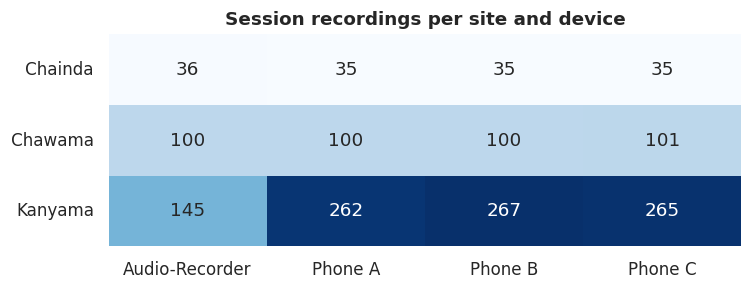

In [5]:
OTHER_AUDIO_EXT = {".mp3", ".m4a", ".flac", ".ogg", ".aac", ".amr", ".3gp", ".opus"}

def parse_device(name):
    if re.search(r"audio[\s_-]*recorder", name, re.I):
        return "Audio-Recorder"
    m = re.search(r"phone[\s_-]*([abc])\b", name, re.I)
    return f"Phone {m.group(1).upper()}" if m else None

def parse_site(name):
    return next((s for s in SITES if s.lower() in name.lower()), None)

rows, other_audio = [], []
for p in DATA_ROOT.rglob("*"):
    if not p.is_file():
        continue
    ext, rel = p.suffix.lower(), p.relative_to(DATA_ROOT)
    if ext in OTHER_AUDIO_EXT:
        other_audio.append(str(rel))
    if ext != ".wav":
        continue
    top = rel.parts[0]
    device = next((parse_device(x) for x in rel.parts[:-1] if parse_device(x)), None)
    site = next((parse_site(x) for x in rel.parts[:-1] if parse_site(x)), None)
    rows.append(dict(path=str(p), top_folder=top, device=device, folder_site=site,
                     raw_stem=p.stem, stem=p.stem.strip()))
files = pd.DataFrame(rows)
print(f"{len(files)} .wav files found")
print("Files whose device could not be parsed:", int(files.device.isna().sum()))
print("Audio files in other formats (not used):", len(other_audio), other_audio[:5])

counts = files.pivot_table(index="folder_site", columns="device", values="path",
                           aggfunc="count", fill_value=0).reindex(columns=DEVICE_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.8))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Session recordings per site and device", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

## Step 2. Read the metadata and the codebook

**What we do.** Load `GHAI_Final_Data_2023.csv` (one row per participant) and the codebook that explains each column. We print a profile of every column: type, how much is missing, and example values.

**Why.** The metadata holds the TB label (`ground_truth_tb`, from Xpert and culture) and the clinical questionnaire. The column names used below come from Zhang et al.'s code, so we check they exist before relying on them.

**What to look for.** About 1,828 participants and 43 columns. Columns with chest X-ray AI scores exist too: they are a different test (an X-ray), so we do **not** use them as model inputs.

In [6]:
meta_path = sorted(DATA_ROOT.rglob("GHAI_Final_Data*.csv"))[0]
codebook_path = next((p for p in DATA_ROOT.rglob("*.csv") if p != meta_path
                      and "metadata and codebook" in str(p).lower()), None)
meta = pd.read_csv(meta_path)
meta["barcode"] = meta["barcode"].astype(str).str.strip()
print(f"Metadata: {meta.shape[0]} rows x {meta.shape[1]} columns | unique barcodes: {meta.barcode.nunique()}")

profile = pd.DataFrame({
    "dtype": meta.dtypes.astype(str),
    "missing_%": (meta.isna().mean() * 100).round(1),
    "n_unique": meta.nunique(),
    "examples": [", ".join(map(str, meta[c].dropna().unique()[:4])) for c in meta.columns],
})
display(profile)
if codebook_path is not None:
    print("Codebook:", codebook_path.name)
    display(pd.read_csv(codebook_path).head(60))

Metadata: 1828 rows x 40 columns | unique barcodes: 1828


,dtype,missing_%,n_unique,examples
sex,object,0.0,2,"m, f"
consent_obtained,int64,0.0,1,1
barcode,object,0.0,1828,"01-399-0258, 01-399-1081, 02-399-0856, 03-399-..."
coughdur,object,0.0,5,"1-2wks, <1wk, >4weeks, no cough"
cough_productive,object,13.2,2,"yes, no"
haemoptysis,object,13.2,2,"no, yes"
chestpain,object,0.2,2,"yes, no"
shortbreath,object,0.2,2,"yes, no"
fever,object,0.0,2,"no, yes"
ngtsweats,object,0.0,2,"yes, no"


Codebook: Google_Health_AI_Final_Codebook.csv


,Google/CIDRZ Health AI,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,variable,data type,options/format,variable name
1,sex,text,m = Male,Sex
2,NaN,NaN,f = Female,NaN
3,consent_obtained,integer,1 = Yes,Consent Obtained
4,NaN,NaN,0 = No,NaN
5,barcode,text,NaN,Study Participant Barcode
6,coughdur,text,no cough,Cough Duration
7,NaN,NaN,<1wk,NaN
8,NaN,NaN,1-2wks,NaN
9,NaN,NaN,3-4wks,NaN


In [7]:
REQUIRED = ["barcode", "ground_truth_tb", "age", "sex", "hiv_status", "prev_tb",
            "tobacco_use", "coughdur", "fever", "weightloss", "ngtsweats"]
missing_cols = [c for c in REQUIRED if c not in meta.columns]
assert not missing_cols, f"Expected columns missing from metadata: {missing_cols}"
dups = meta.barcode.duplicated().sum()
if dups:
    print(f"{dups} duplicated barcodes: keeping the first row for each (as Zhang et al. do).")
    meta = meta.drop_duplicates("barcode", keep="first")
print("All required columns present.")

All required columns present.


## Step 3. Fix mislabeled recordings

**What we do.** Apply Zhang et al.'s relabeling log: a table of files saved under the wrong participant ID, with the correct ID for each. Then we check every recording maps to a participant in the metadata, and that the site in the folder name agrees with the site encoded in the ID (`01-` Kanyama, `02-` Chawama, `03-` Chainda).

**Why.** At the start of each session a staff member reads the participant ID aloud, then types it as the filename. Typos happen. Zhang et al. found them by listening to the announcement and by checking that the same session sounds alike across the four devices recording it. A wrong ID silently attaches one person's cough to another person's TB label, and can put the same person in both training and test data.

**One subtlety.** Some entries form chains, for example `0138 → 0838` and `0838 → 0831`. Each file is looked up **once** by its original name. Applying the rows one after another would wrongly send both files to `0831`.

**What to look for.** About 60 corrected files, zero site mismatches, and a short list of recordings with no metadata row (they are dropped).

**Duplicates.** Where a participant has more than one file for the same device, this cell provisionally keeps the first one. Step 3b replaces that with an evidence-based choice.

In [8]:
CHANGE_LOG_URL = ("https://raw.githubusercontent.com/esl-epfl/tb-cough-generalization/"
                  "main/data/zambia_change_log.csv")
# Offline fallback: a copy of the same file (MIT licence, Zhang et al. 2026).
CHANGE_LOG_EMBEDDED = '''path,from_subject_id,to_subject_id
Kanyama Phone B,01-392-0905,01-399-0905
Kanyama Phone A,01-399-0138,01-399-0838
Kanyama Phone A,01-399-0838,01-399-0831
Kanyama Phone A,01-399-0153,01-399-0853
Kanyama Phone A,01-399-0806 ,01-399-0806
Kanyama Phone B,01-399-1058 (1),01-399-1059
Kanyama Phone C,01-399-8046,01-399-1046
Kanyama Phone A,01-699-0849,01-399-0849
Kanyama Phone A,01-699-0872,01-399-0872
Kanyama Phone A,01-699-0897,01-399-0897
Kanyama Phone A,02-01051,02-399-0691
Kanyama Phone A,02-011011 (1),02-399-0692
Chawama Phone A,02-322-0787,02-399-0787
Kanyama Phone A,02-399 - 0685,02-399-0685
Chawama Phone C,02-39970740,02-399-0740
Chawama Phone A,02-699-0731,02-399-0731
Chawama Phone B,027399-0735,02-399-0735
Chawama Phone B,02_399_0742,02-399-0742
Kanyama Phone C,08-399-0868,01-399-0868
Kanyama Phone A,1-399-0814,01-399-0814
Kanyama Phone A,1-399-0858,01-399-0858
Kanyama Phone A,1-399-0935,01-399-0935
Chawama Phone A,2-399-0760,02-399-0760
Chawama Phone A,2-399-0761,02-399-0761
Chawama Phone B,2-399-0765,02-399-0765
Kanyama Phone A,01-399-0813 (1),01-399-0813
Audio-Recorder-Kanyama,01-399-0837 (1),01-399-0837
Kanyama Phone C,01-399-0864 (1),01-399-0864
Audio-Recorder-Kanyama,01-399-0865 (1),01-399-0865
Audio-Recorder-Chawama,01-399-0878 (1),01-399-0878
Kanyama Phone A,01-399-0956,01-399-0953
Kanyama Phone A,01-399-0956 (1),01-399-0956
Audio-Recorder-Kanyama,01-399-0874 (1),01-399-0873
Kanyama Phone A,01-399-0895 (1),01-399-0893
Kanyama Phone A,01-399-1011 (1),01-399-1012
Kanyama Phone C,02-399-0872 (1),02-399-0872
Audio-Recorder-Chainda-South,03-399-0324 (2),03-399-0324
Chainda South Phone A,3-399-0326,03-399-0326
Audio-Recorder-Chawama,02-399-0725,02-399-0725 (1)
Kanyama Phone B,01-399-0880,01-399-0880 (1)
Audio-Recorder-Chawama,02-399-0760,02-399-0760 (1)
Audio-Recorder-Chawama,02-399-0760 (3),02-399-0760
Audio-Recorder-Chawama,02-399-0784,02-399-0784 (1)
Audio-Recorder-Chawama,02-399-0784 (2),02-399-0784
Audio-Recorder-Kanyama,01-399-0902,01-399-0902 (1)
Audio-Recorder-Kanyama,01-399-0902 (2),01-399-0902
Kanyama Phone B,01-399-0883,01-399-0883 (1)
Audio-Recorder-Kanyama,01-399-0950,01-399-0950 (1)
Kanyama Phone C,01-399-0231,01-399-0931
Audio-Recorder-Kanyama,01-399-0900,01-399-0900 (1)
Audio-Recorder-Kanyama,01-399-0900 (2),01-399-0900
Audio-Recorder-Kanyama,01-399-0918,01-399-0918 (1)
Audio-Recorder-Kanyama,01-399-0918 (2),01-399-0918
Audio-Recorder-Chawama,02-399-0750,02-399-0750 (1)
Audio-Recorder-Chawama,02-399-0750 (2),02-399-0750
Audio-Recorder-Chawama,02-399-0730,02-399-0730 (1)
Audio-Recorder-Chawama,02-399-0730 (2),02-399-0730
Audio-Recorder-Chawama,02-399-0708,02-399-0708 (1)
Audio-Recorder-Chawama,02-399-0708 (2),02-399-0708
Audio-Recorder-Chawama,02-399-0751,02-399-0751 (1)
Audio-Recorder-Chawama,02-399-0751 (2),02-399-0751
Audio-Recorder-Chawama,02-399-0761,02-399-0761 (1)
Audio-Recorder-Chawama,02-399-0761 (2),02-399-0761
'''

def load_change_log():
    if CFG.get("CHANGE_LOG_LOCAL"):
        return pd.read_csv(CFG["CHANGE_LOG_LOCAL"]), "local file"
    try:
        return pd.read_csv(CHANGE_LOG_URL, encoding="utf-8-sig"), "GitHub"
    except Exception as exc:
        print("Could not download the log, using the embedded copy:", exc)
        return pd.read_csv(io.StringIO(CHANGE_LOG_EMBEDDED)), "embedded copy"

log, source = load_change_log()
log = log.dropna(subset=["from_subject_id", "to_subject_id"]).copy()
for c in log.columns:
    log[c] = log[c].astype(str).str.strip()
log = log[log.from_subject_id != log.to_subject_id]          # drop no-op rows
FORWARD = {(r.path, r.from_subject_id): r.to_subject_id for r in log.itertuples()}
for folder, old_id, new_id in CFG.get("EXTRA_RELABELS", []):          # fixes found by the audit
    FORWARD[(folder, old_id)] = new_id
if CFG.get("EXTRA_RELABELS"):
    print(f"Added {len(CFG['EXTRA_RELABELS'])} relabels of your own (EXTRA_RELABELS).")
print(f"Relabeling entries: {len(FORWARD)} (source: {source})")

files["subject_id"] = [FORWARD.get((t, s), s) for t, s in zip(files.top_folder, files.stem)]
files["relabeled"] = files.subject_id != files.stem
files["id_site"] = files.subject_id.map(
    lambda s: next((v for k, v in ID_PREFIX_SITE.items() if s.startswith(k)), None))
files["in_metadata"] = files.subject_id.isin(set(meta.barcode))

print("Files relabeled:", int(files.relabeled.sum()))
print("Files whose ID is not in the metadata (dropped):", int((~files.in_metadata).sum()))
mismatch = files[files.folder_site.notna() & files.id_site.notna() & (files.folder_site != files.id_site)]
print("Folder site disagrees with ID site:", len(mismatch))
if len(mismatch):
    display(mismatch[["top_folder", "stem", "subject_id", "folder_site", "id_site"]].head(20))
dup = files[files.in_metadata].duplicated(["subject_id", "device"], keep=False)
print("Participant-device pairs with more than one file:", int(dup.sum()))
if dup.any():
    display(files[files.in_metadata][dup][["top_folder", "stem", "subject_id"]].head(20))

files = files[files.in_metadata & files.device.notna()].copy()
files["site"] = files.id_site
files_all = files.copy()          # every candidate recording, duplicates included; Step 3b picks one per device
files = files.drop_duplicates(["subject_id", "device"], keep="first")   # provisional, replaced by Step 3b

Relabeling entries: 62 (source: GitHub)
Files relabeled: 54
Files whose ID is not in the metadata (dropped): 164
Folder site disagrees with ID site: 148


,top_folder,stem,subject_id,folder_site,id_site
37,Kanyama Phone B,02-399-0694,02-399-0694,Kanyama,Chawama
42,Kanyama Phone B,02-399-0715,02-399-0715,Kanyama,Chawama
55,Kanyama Phone B,02-399-0698,02-399-0698,Kanyama,Chawama
65,Kanyama Phone B,02-399-0881,02-399-0881,Kanyama,Chawama
72,Kanyama Phone B,02-399-0828,02-399-0828,Kanyama,Chawama
79,Kanyama Phone B,02-399-0693,02-399-0693,Kanyama,Chawama
85,Kanyama Phone B,02-399-0831,02-399-0831,Kanyama,Chawama
90,Kanyama Phone B,02-399-0883,02-399-0883,Kanyama,Chawama
91,Kanyama Phone B,02-399-0691,02-399-0691,Kanyama,Chawama
92,Kanyama Phone B,02-399-0830,02-399-0830,Kanyama,Chawama


Participant-device pairs with more than one file: 30


,top_folder,stem,subject_id
1,Audio-Recorder-Chainda-South,03-399-0324 (2),03-399-0324
28,Audio-Recorder-Chainda-South,03-399-0324,03-399-0324
110,Kanyama Phone B,01-399-0879,01-399-0879
167,Kanyama Phone B,01-399-0882,01-399-0882
211,Kanyama Phone B,01-399-0875,01-399-0875
258,Kanyama Phone B,01-399-0878,01-399-0878
291,Kanyama Phone B,01-399-0876,01-399-0876
326,Audio-Recorder-Chawama,02-399-0689,02-399-0689
440,Audio-Recorder-Kanyama,02-399-0689,02-399-0689
549,Kanyama Phone A,02-399-0726,02-399-0726


## Step 3b. Check that every recording belongs to its participant

**What we do.** For each participant, compare their recordings from the different devices with each other. Four devices recording the same session hear the same sounds at the same moments, so their waveforms line up closely once shifted in time. A file that holds *someone else's* session lines up with nothing.

**Why.** The relabeling log fixes the mistakes Zhang et al. found, but the release still contains:
* the same participant and device stored twice, sometimes in a Chawama folder *and* a Kanyama folder;
* files whose folder site disagrees with the site in their ID;
* IDs whose numbers appear under two site prefixes (e.g. `01-399-0875` and `02-399-0875`).

Before this step the notebook simply kept the first file it found. A wrong file means a participant's "Phone A" coughs are another person's, which breaks the *same cough on three phones* pairing that Notebook 02 depends on.

**How a decision is made.**
1. **What does "unrelated" look like?** Score pairs of recordings from *different* participants. The match threshold is set above that range (and never below `AUDIT_MIN_SCORE`).
2. **Score every pair** of a participant's recordings: 0 means unrelated, 1 means identical apart from a time shift and loudness. The score ignores whether the waveform is flipped upside down, because a microphone's own frequency response can flip it; only how well the shapes line up counts.
3. **Pick one file per device** so that the largest possible group of recordings all match each other. Files outside that group are excluded.
4. **When the evidence cannot decide** (for example, only two devices and they disagree), exclude both. Excluding a participant costs a little data; keeping a wrong file corrupts the comparison.
5. **Near-silent files** are excluded. **A participant with a single recording** cannot be checked and is kept, flagged as unverified.

**Suggested ID fixes.** Every excluded, unverified or site-mismatched file is also compared with participants who share its 4-digit number under another prefix. Matches are listed as ready-to-paste lines for `EXTRA_RELABELS`. They are **not** applied automatically: someone should look at them first.

**What to look for.** Two clearly separated humps in the score histogram (unrelated pairs near 0, same-session pairs well above), most participants marked *consistent*, and a short, explainable list of exclusions.

In [9]:
import itertools
AUDIT_SR, SILENT_RMS = 4_000, 1e-4
AUDIT_FILES, AUDIT_PAIRS, AUDIT_PARTS = OUT / "audit_files.csv", OUT / "audit_pairs.csv", OUT / "audit_participants.csv"

def load_ds(path):
    y, _ = librosa.load(path, sr=AUDIT_SR, mono=True)
    return (y - y.mean()).astype(np.float32)

def pair_score(a, b):
    # Peak of the normalised cross-correlation: 0 = unrelated, 1 = identical up to a time shift and gain.
    den = float(np.linalg.norm(a) * np.linalg.norm(b))
    if den < 1e-8:
        return np.nan, 0
    c = correlate(a, b, mode="full", method="fft")
    k = int(np.argmax(np.abs(c)))
    return float(min(abs(c[k]) / den, 1.0)), int(np.sign(c[k]))

def components(nodes, S, thr):
    parent = {n: n for n in nodes}
    def root(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for a, b in itertools.combinations(nodes, 2):
        if S[a, b] >= thr:
            parent[root(a)] = root(b)
    groups = {}
    for n in nodes:
        groups.setdefault(root(n), []).append(n)
    return list(groups.values())

def audit_participant(sid, recs, thr):
    recs = recs.reset_index(drop=True)
    sig = [load_ds(p) for p in recs.path]
    rms = [float(np.sqrt(np.mean(x ** 2))) if len(x) else 0.0 for x in sig]
    n = len(recs); S = np.zeros((n, n)); SIGN = np.zeros((n, n), int); pairs = []
    for i, j in itertools.combinations(range(n), 2):
        s, sg = pair_score(sig[i], sig[j])
        S[i, j] = S[j, i] = 0.0 if np.isnan(s) else s; SIGN[i, j] = SIGN[j, i] = sg
        pairs.append(dict(subject_id=sid, file_a=recs.top_folder[i] + "/" + recs.raw_stem[i], device_a=recs.device[i],
                          file_b=recs.top_folder[j] + "/" + recs.raw_stem[j], device_b=recs.device[j],
                          score=s, peak_sign=sg, same_device=recs.device[i] == recs.device[j]))
    alive = [i for i in range(n) if rms[i] >= SILENT_RMS]
    by_dev = {}
    for i in alive:
        by_dev.setdefault(recs.device[i], []).append(i)
    best, keep = None, []
    for combo in itertools.product(*by_dev.values()):
        groups = components(list(combo), S, thr)
        top = max(len(g) for g in groups)
        tops = [g for g in groups if len(g) == top]
        within = sum(S[a, b] for g in tops for a, b in itertools.combinations(g, 2))
        key = (top, len(tops) == 1, within)
        if best is None or key > best[0]:
            best = (key, combo, tops)
    chosen = set(best[1]) if best else set()
    if not alive:
        pstatus = "silent"
    elif len(chosen) == 1:
        pstatus, keep = "single_recording", list(chosen)
    elif best[0][0] < 2 or not best[0][1]:
        pstatus = "conflict"
    else:
        keep = best[2][0]
        pstatus = "consistent" if len(keep) == len(chosen) else "some_excluded"
    rows = []
    for i in range(n):
        others = [k for k in keep if recs.device[k] != recs.device[i] and k != i]
        best_match = max((S[i, k] for k in others), default=np.nan)
        if rms[i] < SILENT_RMS:
            status = "excluded_silent"
        elif i in keep:
            status = "kept_unverified" if pstatus == "single_recording" else "kept"
        elif pstatus == "conflict":
            status = "excluded_conflict"
        elif i not in chosen:
            twin = [k for k in keep if recs.device[k] == recs.device[i]]
            if twin and S[i, twin[0]] >= 0.95:
                status = "duplicate_identical"
            elif not np.isnan(best_match) and best_match >= thr:
                status = "duplicate_alternative"
            else:
                status = "duplicate_other_session"
        else:
            status = "excluded_no_match"
        rows.append(dict(subject_id=sid, device=recs.device[i], top_folder=recs.top_folder[i], stem=recs.raw_stem[i],
                         path=recs.path[i], folder_site=recs.folder_site[i], id_site=recs.id_site[i],
                         rms=round(rms[i], 6), best_match_with_kept=round(best_match, 3) if not np.isnan(best_match) else np.nan,
                         status=status, participant_status=pstatus))
    return rows, pairs

def null_scores(n_files=120, n_pairs=300, seed=CFG["SEED"]):
    # Similarity of recordings from DIFFERENT participants: what "unrelated" looks like in this dataset
    rng = np.random.default_rng(seed)
    per = files_all.groupby("subject_id").path.apply(list)
    pick = rng.choice(per.index, size=min(n_files, len(per)), replace=False)
    sigs = {s: load_ds(rng.choice(per[s])) for s in pick}
    keys, out = list(sigs), []
    for _ in range(n_pairs):
        a, b = rng.choice(len(keys), 2, replace=False)
        s, _ = pair_score(sigs[keys[a]], sigs[keys[b]])
        if not np.isnan(s):
            out.append(s)
    return np.array(out)

def run_parallel(func, items):
    try:
        from joblib import Parallel, delayed
        jobs = (delayed(func)(*it) for it in items)
        try:
            from tqdm.auto import tqdm
            return list(tqdm(Parallel(n_jobs=-1, return_as="generator")(jobs), total=len(items), desc="auditing"))
        except TypeError:
            return Parallel(n_jobs=-1)(jobs)
    except ImportError:
        return [func(*it) for it in items]

if CFG.get("RUN_AUDIT", True):
    t0 = time.time()
    null = null_scores()
    AUDIT_THR = max(CFG["AUDIT_MIN_SCORE"], float(np.quantile(null, 0.99)))
    print(f"Unrelated recordings: median similarity {np.median(null):.3f}, 99th percentile {np.quantile(null, 0.99):.3f}"
          f" -> match threshold {AUDIT_THR:.3f}")
    if AUDIT_THR > 0.3:
        print("WARNING: unrelated recordings score unusually high; check the histogram below before trusting the audit.")
    groups = [(sid, g, AUDIT_THR) for sid, g in files_all.groupby("subject_id")]
    results = run_parallel(audit_participant, groups)
    audit = pd.DataFrame([r for rows, _ in results for r in rows])
    audit_pairs = pd.DataFrame([p for _, pairs in results for p in pairs])

    # Suggested ID fixes: compare doubtful files with participants sharing the same 4-digit number
    doubtful = audit[audit.status.isin(["excluded_no_match", "excluded_conflict", "kept_unverified",
                                        "duplicate_other_session"]) | ((audit.folder_site != audit.id_site) & audit.folder_site.notna())]
    kept_by_subject = audit[audit.status.isin(["kept", "kept_unverified"])].groupby("subject_id").path.apply(list)
    suggestions = []
    for r in doubtful.itertuples():
        num = r.subject_id[-4:]
        others = [s for s in kept_by_subject.index if s != r.subject_id and s.endswith(num)]
        if not others:
            continue
        x = load_ds(r.path)
        for s in others:
            sc = max(pair_score(x, load_ds(p))[0] for p in kept_by_subject[s])
            if sc >= AUDIT_THR:
                suggestions.append(dict(folder=r.top_folder, file=r.stem, listed_as=r.subject_id, device=r.device,
                                        matches_participant=s, similarity=round(sc, 3), current_status=r.status))
    suggestions = pd.DataFrame(suggestions, columns=["folder", "file", "listed_as", "device", "matches_participant",
                                                     "similarity", "current_status"])
    parts = audit.groupby("subject_id").agg(participant_status=("participant_status", "first"),
                                            files_found=("path", "size"),
                                            devices_found=("device", "nunique"),
                                            devices_kept=("status", lambda s: int(s.isin(["kept", "kept_unverified"]).sum())))
    audit.to_csv(AUDIT_FILES, index=False); audit_pairs.to_csv(AUDIT_PAIRS, index=False)
    parts.to_csv(AUDIT_PARTS); suggestions.to_csv(OUT / "audit_suggested_relabels.csv", index=False)

    before = files.groupby(["site", "device"]).subject_id.nunique()
    files = files_all.merge(audit[["path", "status"]], on="path")
    files = files[files.status.isin(["kept", "kept_unverified"])].drop(columns="status").copy()
    assert not files.duplicated(["subject_id", "device"]).any()
    print(f"Audit finished in {(time.time() - t0) / 60:.1f} min")
else:
    print("RUN_AUDIT is False: keeping the first file found for each participant and device (not recommended).")

Unrelated recordings: median similarity 0.038, 99th percentile 0.092 -> match threshold 0.150


auditing:   0%|          | 0/363 [00:00<?, ?it/s]

Audit finished in 6.2 min


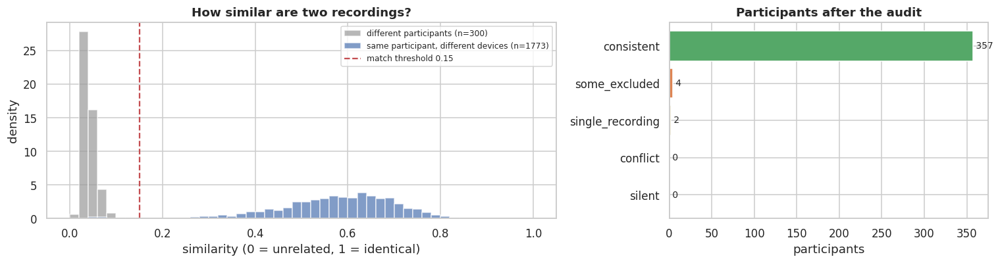

What happened to each file:


,files
status,
kept,1296
duplicate_alternative,12
excluded_no_match,4
duplicate_other_session,3
kept_unverified,2


Same-participant pairs below the threshold: 20 of 1773.

Participant-device pairs with more than one file: 15 (which file was kept, and why the other was not):


,subject_id,device,top_folder,stem,best_match_with_kept,status
273,01-399-0875,Phone B,Chawama Phone B,01-399-0875,0.663,duplicate_alternative
270,01-399-0875,Phone B,Kanyama Phone B,01-399-0875,0.747,kept
274,01-399-0876,Phone B,Kanyama Phone B,01-399-0876,0.461,duplicate_alternative
277,01-399-0876,Phone B,Chawama Phone B,01-399-0876,0.471,kept
278,01-399-0878,Phone B,Kanyama Phone B,01-399-0878,0.414,duplicate_alternative
281,01-399-0878,Phone B,Chawama Phone B,01-399-0878,0.501,kept
285,01-399-0879,Phone B,Chawama Phone B,01-399-0879,0.497,duplicate_alternative
282,01-399-0879,Phone B,Kanyama Phone B,01-399-0879,0.547,kept
295,01-399-0882,Phone B,Chawama Phone B,01-399-0882,0.566,duplicate_alternative
292,01-399-0882,Phone B,Kanyama Phone B,01-399-0882,0.635,kept



Excluded recordings: 4


,subject_id,device,top_folder,stem,rms,best_match_with_kept,status
131,01-399-0837,Audio-Recorder,Audio-Recorder-Kanyama,01-399-0837,0.007204,0.064,excluded_no_match
235,01-399-0865,Audio-Recorder,Audio-Recorder-Kanyama,01-399-0865,0.002325,0.124,excluded_no_match
279,01-399-0878,Audio-Recorder,Audio-Recorder-Kanyama,01-399-0878,0.023702,0.068,excluded_no_match
615,01-399-0978,Phone B,Kanyama Phone B,01-399-0978,0.038904,0.065,excluded_no_match



Suggested ID fixes: 0 (review, then paste the lines you accept into EXTRA_RELABELS)

Participants per site and device, before and after the audit:


before_audit  after_audit  change
site    device                                           
Chainda Audio-Recorder            34           34       0
        Phone A                   34           34       0
        Phone B                   34           34       0
        Phone C                   34           34       0
Chawama Audio-Recorder            89           89       0
        Phone A                  109          109       0
        Phone B                  102          102       0
        Phone C                  109          109       0
Kanyama Audio-Recorder           119          116      -3
        Phone A                  208          208       0
        Phone B                  215          214      -1
        Phone C                  215          215       0

In [10]:
if CFG.get("RUN_AUDIT", True):
    same = audit_pairs[~audit_pairs.same_device].score.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
    bins = np.linspace(0, 1, 51)
    axes[0].hist(null, bins=bins, alpha=0.7, color="#999999", label=f"different participants (n={len(null)})", density=True)
    axes[0].hist(same, bins=bins, alpha=0.7, color="#4C72B0", label=f"same participant, different devices (n={len(same)})", density=True)
    axes[0].axvline(AUDIT_THR, color="#C44E52", ls="--", label=f"match threshold {AUDIT_THR:.2f}")
    axes[0].set(title="How similar are two recordings?", xlabel="similarity (0 = unrelated, 1 = identical)", ylabel="density")
    axes[0].legend(fontsize=8)
    order = ["consistent", "some_excluded", "single_recording", "conflict", "silent"]
    counts = parts.participant_status.value_counts().reindex(order).fillna(0)
    axes[1].barh(counts.index[::-1], counts.values[::-1], color=["#999999", "#C44E52", "#CCB974", "#DD8452", "#55A868"])
    for y, v in enumerate(counts.values[::-1]):
        axes[1].text(v, y, f" {int(v)}", va="center", fontsize=9)
    axes[1].set(title="Participants after the audit", xlabel="participants")
    plt.tight_layout(); plt.show()

    print("What happened to each file:")
    display(audit.status.value_counts().rename("files").to_frame())
    print(f"Same-participant pairs below the threshold: {(same < AUDIT_THR).sum()} of {len(same)}.")

    dups = audit[audit.duplicated(["subject_id", "device"], keep=False)].sort_values(["subject_id", "device", "status"])
    print(f"\nParticipant-device pairs with more than one file: {dups.groupby(['subject_id', 'device']).ngroups} "
          "(which file was kept, and why the other was not):")
    display(dups[["subject_id", "device", "top_folder", "stem", "best_match_with_kept", "status"]].head(40))

    excl = audit[audit.status.str.startswith("excluded")]
    print(f"\nExcluded recordings: {len(excl)}")
    display(excl[["subject_id", "device", "top_folder", "stem", "rms", "best_match_with_kept", "status"]].head(40))

    print(f"\nSuggested ID fixes: {len(suggestions)} (review, then paste the lines you accept into EXTRA_RELABELS)")
    if len(suggestions):
        display(suggestions)
        print("EXTRA_RELABELS = [")
        for r in suggestions.itertuples():
            print(f'    ("{r.folder}", "{r.file}", "{r.matches_participant}"),   # similarity {r.similarity}')
        print("]")

    after = files.groupby(["site", "device"]).subject_id.nunique()
    change = pd.DataFrame({"before_audit": before, "after_audit": after}).fillna(0).astype(int)
    change["change"] = change.after_audit - change.before_audit
    print("\nParticipants per site and device, before and after the audit:")
    display(change)

## Step 4. Exploratory analysis: who are the participants?

**What we do.** Translate the questionnaire answers into numbers using exactly the same mapping as Zhang et al., then look at how TB status relates to site and to each clinical variable.

**Why.** The clinical variables are the reference model (Baseline B), so we need to understand them. They also tell us what audio has to beat: if weight loss already separates TB well, audio must add something beyond it.

**One mapping choice to know about.** Zhang et al. code smoking answered *not disclosed* as *never smoked*. We keep that for comparability, but it is a judgement call worth revisiting.

**What to look for.** TB prevalence that differs by site (Zambia data published elsewhere: about 9 to 10% in Chawama, 21 to 22% in Kanyama, very low in Chainda-South), and symptoms such as weight loss and night sweats that are more common among TB-positive participants.

In [11]:
CLIN_SPEC = {   # model feature: (metadata column, value mapping); identical to Zhang et al.
    "age":          ("age", None),
    "male":         ("sex", {"f": 0, "m": 1}),
    "smoker":       ("tobacco_use", {"never": 0, "not disclosed": 0, "current": 1, "stopped": 1}),
    "hiv_pos":      ("hiv_status", {"neg": 0, "pos": 1}),
    "prev_tb":      ("prev_tb", {"no": 0, "yes": 1}),
    "cough_days":   ("coughdur", {"<1wk": 3.5, "1-2wks": 10.5, "3-4wks": 24.5, ">4weeks": 35.0, "no cough": 0.0}),
    "fever":        ("fever", {"no": 0, "yes": 1}),
    "weight_loss":  ("weightloss", {"no": 0, "yes": 1}),
    "night_sweats": ("ngtsweats", {"no": 0, "yes": 1}),
}
CLIN_FEATURES = list(CLIN_SPEC)
CLIN_CONTINUOUS = ["age", "cough_days"]

def norm_str(s):
    return s.astype(str).str.strip().str.lower().replace({"nan": np.nan, "": np.nan})

clin = pd.DataFrame({"subject_id": meta.barcode})
clin["label"] = norm_str(meta.ground_truth_tb).map({"neg": 0, "pos": 1})
clin["site"] = clin.subject_id.map(lambda s: next((v for k, v in ID_PREFIX_SITE.items() if s.startswith(k)), None))
unmapped = {}
for feat, (col, mapping) in CLIN_SPEC.items():
    if mapping is None:
        clin[feat] = pd.to_numeric(meta[col], errors="coerce")
    else:
        raw = norm_str(meta[col])
        clin[feat] = raw.map(mapping)
        bad = raw[raw.notna() & clin[feat].isna()].value_counts()
        if len(bad):
            unmapped[col] = bad.to_dict()
clin = clin.reset_index(drop=True)
print("Raw values that did not match the mapping (become missing):", unmapped or "none")
print(f"Participants with a TB label: {clin.label.notna().sum()} of {len(clin)}")
display(clin.head())

Raw values that did not match the mapping (become missing): none
Participants with a TB label: 1828 of 1828


,subject_id,label,site,age,male,smoker,hiv_pos,prev_tb,cough_days,fever,weight_loss,night_sweats
0,01-399-0258,0,Kanyama,31,1,1.0,0.0,0.0,10.5,0,1,1
1,01-399-1081,0,Kanyama,58,1,1.0,1.0,1.0,3.5,1,1,1
2,02-399-0856,0,Chawama,24,1,1.0,0.0,0.0,3.5,1,1,1
3,03-399-0290,0,Chainda,25,0,0.0,1.0,1.0,10.5,0,1,1
4,01-399-0744,0,Kanyama,30,1,1.0,1.0,1.0,3.5,1,0,1


,n,tb_pos,prevalence_%
site,,,
Chainda,223,11,4.9
Chawama,748,61,8.2
Kanyama,857,133,15.5


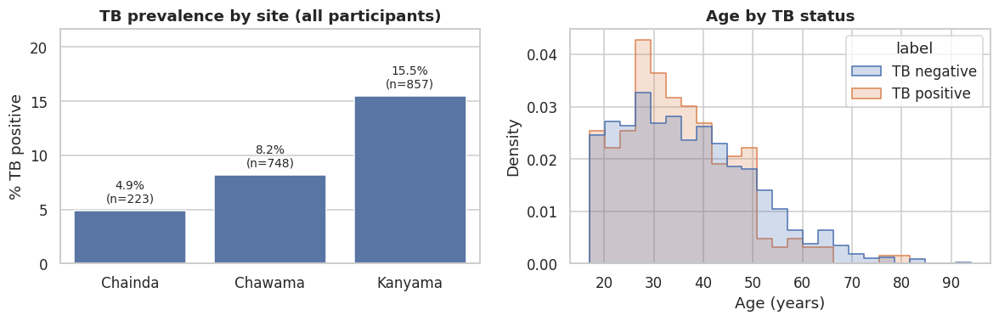

In [12]:
lab = clin[clin.label.notna()]
prev = lab.groupby("site").agg(n=("label", "size"), tb_pos=("label", "sum"))
prev["prevalence_%"] = (100 * prev.tb_pos / prev.n).round(1)
display(prev)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.barplot(x=prev.index, y=prev["prevalence_%"], ax=axes[0], color="#4C72B0")
for i, (n, p) in enumerate(zip(prev.n, prev["prevalence_%"])):
    axes[0].text(i, p + 0.5, f"{p}%\n(n={n})", ha="center", va="bottom", fontsize=9)
axes[0].set(title="TB prevalence by site (all participants)", ylabel="% TB positive", xlabel="",
            ylim=(0, max(prev["prevalence_%"]) * 1.4))
sns.histplot(data=lab, x="age", hue=lab.label.map({0: "TB negative", 1: "TB positive"}),
             stat="density", common_norm=False, element="step", bins=25, ax=axes[1])
axes[1].set(title="Age by TB status", xlabel="Age (years)")
plt.tight_layout(); plt.show()

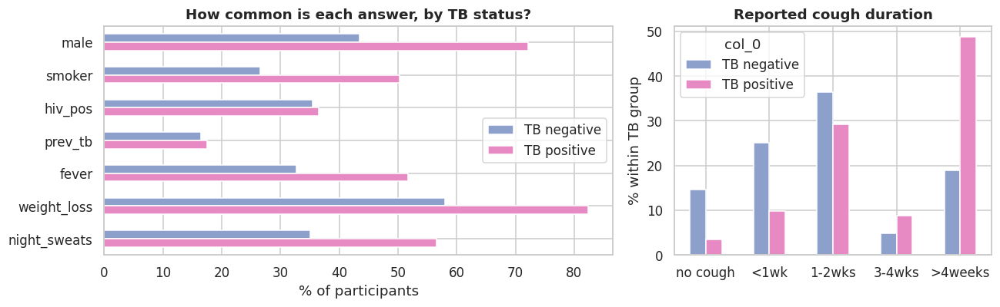

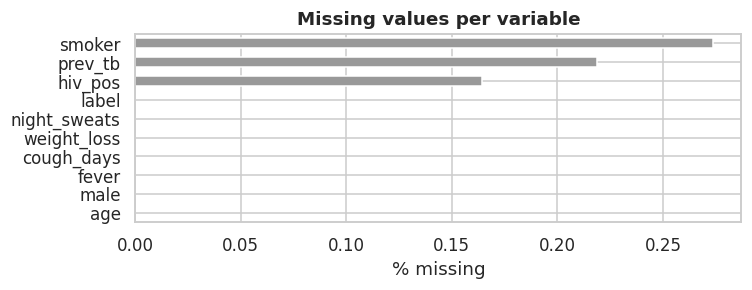

Complete cases (all 9 variables + label): 1823 (TB+ 205). Zhang et al. report 1,823 (205 TB+).


In [13]:
binary = ["male", "smoker", "hiv_pos", "prev_tb", "fever", "weight_loss", "night_sweats"]
rates = lab.groupby("label")[binary].mean().T * 100
rates.columns = ["TB negative", "TB positive"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
rates.plot.barh(ax=axes[0], color=["#8DA0CB", "#E78AC3"])
axes[0].set(title="How common is each answer, by TB status?", xlabel="% of participants")
axes[0].invert_yaxis()
cd = norm_str(meta.loc[clin.label.notna().values, "coughdur"])
ct = pd.crosstab(cd.values, lab.label.map({0: "TB negative", 1: "TB positive"}).values, normalize="columns") * 100
order = [c for c in ["no cough", "<1wk", "1-2wks", "3-4wks", ">4weeks"] if c in ct.index]
ct.loc[order].plot.bar(ax=axes[1], color=["#8DA0CB", "#E78AC3"])
axes[1].set(title="Reported cough duration", ylabel="% within TB group", xlabel="")
plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

miss = (clin[CLIN_FEATURES + ["label"]].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
miss.plot.barh(ax=ax, color="#999999")
ax.set(title="Missing values per variable", xlabel="% missing")
plt.tight_layout(); plt.show()
complete = clin.dropna(subset=CLIN_FEATURES + ["label"])
print(f"Complete cases (all 9 variables + label): {len(complete)} "
      f"(TB+ {int(complete.label.sum())}). Zhang et al. report 1,823 (205 TB+).")

## Step 5. Exploratory analysis: what does the audio look like?

**What we do.** (a) Count which devices each participant was recorded on. (b) Read every file's header (no decoding, so it is fast) to get duration and sample rate. (c) Listen to and look at one participant recorded on all four devices at once.

**Why.** Our whole design rests on the *same cough* being captured by several phones. Step (a) tells us how many participants have all three phones, which is the paired cohort for Notebook 02. Step (c) makes the device problem visible: identical coughs, different-looking recordings.

**What to look for.** Most participants on all three phones; session lengths of a minute or two; and in the spectrograms, a low-tier phone that cuts off high frequencies that the recorder keeps.

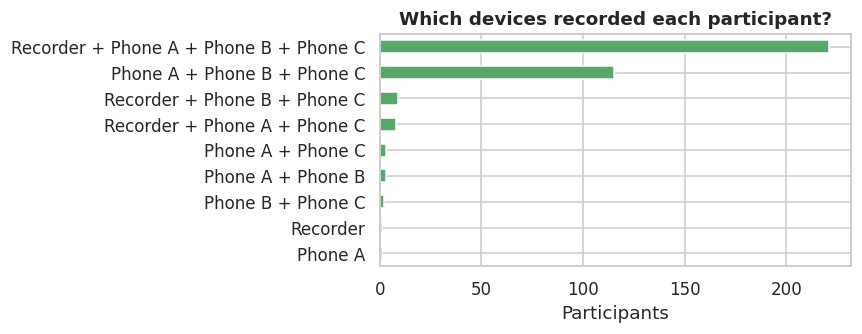

participants                  tb_pos                
site                  Chainda Chawama Kanyama Chainda Chawama Kanyama
device                                                               
Audio-Recorder             34      89     116       1       9      25
Phone A                    34     109     208       1      10      46
Phone B                    34     102     214       1      10      48
Phone C                    34     109     215       1      10      48
all three phones           34      98     204       1      10      46

Participants with audio and a label: 363


In [14]:
have = files.pivot_table(index="subject_id", columns="device", values="path", aggfunc="count",
                         fill_value=0).reindex(columns=DEVICE_ORDER, fill_value=0).astype(bool)
combo = have.apply(lambda r: " + ".join(d.replace("Audio-Recorder", "Recorder") for d in DEVICE_ORDER if r[d]), axis=1)
fig, ax = plt.subplots(figsize=(8, 3.2))
combo.value_counts().head(10).sort_values().plot.barh(ax=ax, color="#55A868")
ax.set(title="Which devices recorded each participant?", xlabel="Participants")
plt.tight_layout(); plt.show()

aud = have.join(clin.set_index("subject_id")[["site", "label"]], how="left")
aud["all_three_phones"] = aud[["Phone A", "Phone B", "Phone C"]].all(axis=1)
tab = []
for site in SITES:
    for dev in DEVICE_ORDER:
        s = aud[(aud.site == site) & aud[dev] & aud.label.notna()]
        tab.append(dict(site=site, device=dev, participants=len(s), tb_pos=int(s.label.sum()),
                        tb_rate_pct=round(100 * s.label.mean(), 1) if len(s) else np.nan))
    s = aud[(aud.site == site) & aud.all_three_phones & aud.label.notna()]
    tab.append(dict(site=site, device="all three phones", participants=len(s), tb_pos=int(s.label.sum()),
                    tb_rate_pct=round(100 * s.label.mean(), 1) if len(s) else np.nan))
coverage = pd.DataFrame(tab)
display(coverage.pivot(index="device", columns="site", values=["participants", "tb_pos"]))
print("Participants with audio and a label:", int(aud.label.notna().sum()))

,files,sample_rates,channels,median_duration_s
device,,,,
Audio-Recorder,239,[44100],[2],45.9639
Phone A,351,[192000],[2],42.2000
Phone B,350,[192000],[2],42.1600
Phone C,358,[192000],[2],42.2000


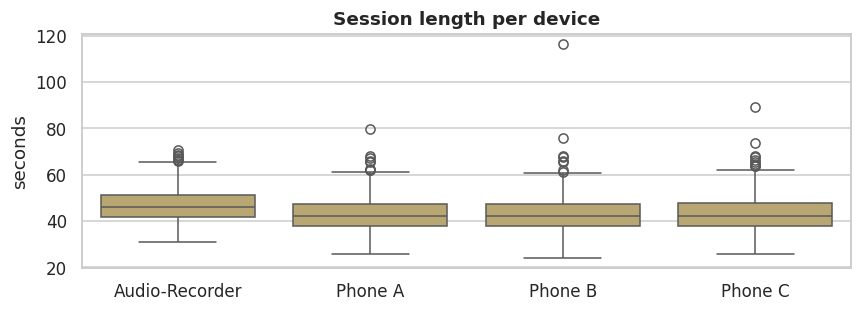

Unreadable files: 0


In [15]:
def header(path):
    try:
        i = sf.info(path)
        return pd.Series(dict(sr=i.samplerate, duration_s=i.duration, channels=i.channels))
    except Exception:
        return pd.Series(dict(sr=np.nan, duration_s=np.nan, channels=np.nan))

files = files.join(files.path.apply(header))
display(files.groupby("device").agg(files=("path", "size"), sample_rates=("sr", lambda s: sorted(s.dropna().unique().astype(int))),
                                    channels=("channels", lambda s: sorted(s.dropna().unique().astype(int))),
                                    median_duration_s=("duration_s", "median")))
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(data=files, x="device", y="duration_s", order=DEVICE_ORDER, ax=ax, color="#C4AD66")
ax.set(title="Session length per device", xlabel="", ylabel="seconds")
plt.tight_layout(); plt.show()
print("Unreadable files:", int(files.sr.isna().sum()))

Example participant 01-399-0803 | TB label: 1 | devices: ['Audio-Recorder', 'Phone A', 'Phone B', 'Phone C']
Shift applied to line up with the reference (seconds): [0.0, 7.398, 4.63, 6.027]


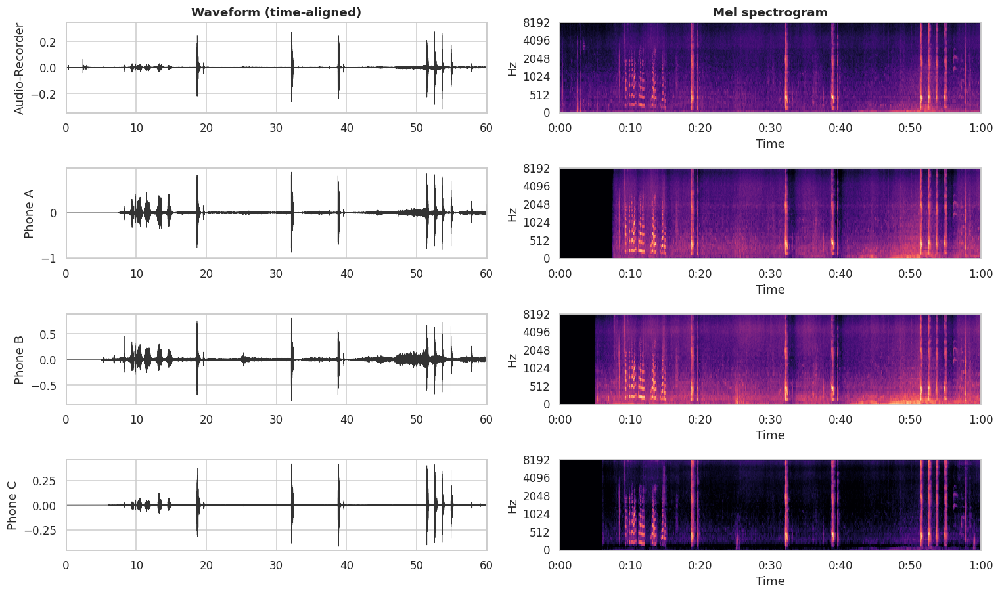

**Recorder**

**Phone A (Pixel 3a, low tier)**

**Phone B (Galaxy A12, mid tier)**

**Phone C (Galaxy A22, high tier)**

In [16]:
def load_mono(path, sr=SR):
    y, _ = librosa.load(path, sr=sr, mono=True)
    return y.astype(np.float32)

def align_to_reference(audios, sr=SR, align_sr=4_000):
    # Zhang et al.: line every recording up with the first one (the reference) by finding the
    # time shift where the two waveforms are most similar (cross-correlation at 4 kHz for speed).
    # Our change: FFT-based correlation. Same shift, about 100-200x faster on long sessions.
    # We also return a 0-1 similarity score: a low value suggests a wrong file or a bad recording.
    ref_ds = librosa.resample(audios[0], orig_sr=sr, target_sr=align_sr)
    aligned, lags, quality = [audios[0]], [0], [1.0]
    for audio in audios[1:]:
        aud_ds = librosa.resample(audio, orig_sr=sr, target_sr=align_sr)
        corr = correlate(ref_ds, aud_ds, mode="full", method="fft")
        k = int(np.argmax(corr))
        if -corr.min() > 1.5 * corr.max():       # microphone wired with inverted polarity
            k = int(np.argmin(corr))
        lag = int((k - len(aud_ds) + 1) * sr / align_sr)
        den = np.linalg.norm(ref_ds) * np.linalg.norm(aud_ds)
        quality.append(float(abs(corr[k]) / den) if den > 1e-8 else float("nan"))
        aligned.append(np.pad(audio, (lag, 0)) if lag > 0 else audio[-lag:])
        lags.append(lag)
    n = min(len(a) for a in aligned)
    return [a[:n] for a in aligned], lags, quality

def device_paths(subject_id):
    sub = files[files.subject_id == subject_id]
    return {d: sub.loc[sub.device == d, "path"].iloc[0] for d in DEVICE_ORDER if (sub.device == d).any()}

n_dev = files.groupby("subject_id").device.nunique()
lab_by = clin.set_index("subject_id").label
cands = [s for s in n_dev[n_dev == n_dev.max()].index if lab_by.get(s) == 1] or list(n_dev[n_dev == n_dev.max()].index)
EXAMPLE_ID = sorted(cands)[0]
ex_paths = device_paths(EXAMPLE_ID)
ex_devices = list(ex_paths)
ex_aligned, ex_lags, ex_quality = align_to_reference([load_mono(ex_paths[d]) for d in ex_devices])
print(f"Example participant {EXAMPLE_ID} | TB label: {lab_by.get(EXAMPLE_ID)} | devices: {ex_devices}")
print("Shift applied to line up with the reference (seconds):", [round(l / SR, 3) for l in ex_lags])

show_s = min(60, len(ex_aligned[0]) / SR)
fig, axes = plt.subplots(len(ex_devices), 2, figsize=(14, 2.1 * len(ex_devices)), squeeze=False)
for i, (d, y) in enumerate(zip(ex_devices, ex_aligned)):
    seg = y[: int(show_s * SR)]
    axes[i, 0].plot(np.arange(len(seg)) / SR, seg, lw=0.4, color="#333333")
    axes[i, 0].set(ylabel=d, xlim=(0, show_s))
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=seg, sr=SR, n_mels=64, fmax=8000), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="mel", fmax=8000, ax=axes[i, 1], cmap="magma")
    axes[i, 1].set(ylabel="Hz")
axes[0, 0].set_title("Waveform (time-aligned)"); axes[0, 1].set_title("Mel spectrogram")
plt.tight_layout(); plt.show()
for d, y in zip(ex_devices, ex_aligned):
    display(Markdown(f"**{DEVICE_LABEL[d]}**"), Audio(y[: int(show_s * SR)], rate=SR))

**Reading the figure.** Each row is the same moment recorded by a different device. The first seconds are a staff member announcing the participant ID; the sharp bursts after that are coughs. Compare the spectrograms top to bottom: the bright regions sit at the same times (same coughs), but how high they reach in frequency and how much background they carry depends on the device. That difference is what a model can latch onto instead of the disease.

## Step 6. Cut the sessions into individual coughs (Zhang et al.'s extractor)

**What we do.** Turn each session into short clips, one cough each. The recipe has five stages:

```
 4 recordings of one session
        |
 (1) ALIGN       shift every device so all four line up in time (cross-correlation)
        |
 (2) DETECT      cut the reference recording into 2-second windows; ask CLAP
                 "white noise, people talking, or coughing sound?"
                 ignore the first ~10 s (ID announcement) and quiet windows
        |
 (3) SINGLES     the first 3 groups of cough windows = the 3 single coughs;
                 trim each to its loud part using the energy envelope;
                 use the median start/end across devices
        |
 (4) SEQUENCE    the remaining cough windows = the multi-cough episode;
                 find each cough as a peak in the energy envelope;
                 keep a segment only if at least half the devices agree
        |
 (5) KEEP        clips shorter than 1 second, cut at the SAME times on every device
```

**Why it matters for us.** Because every device is cut at identical times, **clip number *k* is the same cough on every phone**. That pairing is exactly what Notebook 02 needs to measure how much a prediction moves when only the phone changes.

**What CLAP is.** A model trained to match sounds with text descriptions. Here it is used "zero-shot": nobody trained it on these coughs; it simply judges which of three phrases fits each window best.

### Strengths and weaknesses of the extractor

| | Point | What it means for us |
|---|---|---|
| ✔ | Uses all simultaneous devices | Identical cut times across devices, so clips pair up for the device analysis. |
| ✔ | Skips the ID announcement | Speech at the start is not mistaken for a cough, and spoken IDs do not leak into clips. |
| ✔ | Cross-device consensus for the multi-cough episode | Noise picked up by one device alone is ignored. |
| ✔ | Drops clips of 1 second or more | Removes most segmentation failures (two coughs merged, speech included). |
| ✘ | Original correlation is quadratic in session length | Many hours on the full dataset. **Fixed here** with an FFT version giving the same shift. |
| ✘ | CLAP run one window at a time, on CPU, via a temporary file each | Slow. **Fixed here** by batching on GPU and only scoring windows that pass the loudness gate; labels are unchanged. |
| ✘ | Detection runs on one reference device only | The recorder when present, otherwise Phone A, the lowest-tier phone. Detection quality varies between participants for that reason. |
| ✘ | No check that alignment succeeded | A misaligned device gets cut at the wrong times. **We add** an alignment score per device so suspect sessions can be reviewed. |
| ✘ | Zero-shot detector, never validated against hand labels | We cannot state its accuracy. Spot-check clips by ear (Step 6c). |
| ✘ | Assumes the protocol order: 3 singles, then an episode | If a participant deviated, single and episode coughs get mixed up. Clips are still kept; only the label is affected. |
| ✘ | Episode windows that are not adjacent are glued together before peak finding | A clip can straddle an artificial join. **We count** how often (`spans_join`). |
| ✘ | Skip rule is off by one window | Code skips the first 10 s, not the 8 s stated; a cough at 8 to 10 s is lost. Kept as is for comparability. |
| ✘ | Cough type (single vs episode) not saved | **We record it**, since it may matter for analysis later. |

None of our changes move a single cut point: the clips are the ones Zhang et al.'s code would produce. We only make it faster and record extra information.

In [17]:
import msclap.CLAPWrapper as cw

def preprocess_text_v5(self, text_queries):
    # msclap's preprocess_text, calling the tokenizer directly (transformers 5 removed encode_plus)
    tokenized = []
    for ttext in text_queries:
        if "gpt" in self.args.text_model:
            ttext = ttext + " <|endoftext|>"
        tok = self.tokenizer(text=ttext, add_special_tokens=True, max_length=self.args.text_len,
                             padding="max_length", truncation=True, return_tensors="pt")
        for key in self.token_keys:
            v = tok[key].reshape(-1)
            tok[key] = v.cuda() if self.use_cuda and torch.cuda.is_available() else v
        tokenized.append(tok)
    return self.default_collate(tokenized)

cw.CLAPWrapper.preprocess_text = preprocess_text_v5

In [18]:
# ---- Zhang et al. (2026) segmentation parameters, unchanged -------------------------------
CLAP_LABELS = ["white noise", "people talking", "coughing sound"]
COUGH_IDX = 2
WIN_S, SKIP_S = 2.0, 8.0                 # 2-s windows; skip rule (see the off-by-one note above)
N_SINGLE, MAX_CLIP_S, CONSENSUS = 3, 1.0, 0.5
ENERGY_WINDOW_S, ENERGY_THRESHOLD = 0.05, 0.05
ENERGY_PRE_PAD_S, ENERGY_POST_PAD_S = 0.05, 0.25
PEAK_THRESH_FRAC, PEAK_DIST_S, MIN_BASELINE_S = 0.30, 0.50, 0.10

class ClapDetector:
    # CLAP zero-shot window labelling (Zhang et al.), batched and on GPU when available.
    def __init__(self):
        import msclap.CLAPWrapper as cw
        from msclap import CLAP
        def read_audio_sf(self, audio_path, resample=True):
            # Same behaviour as msclap's read_audio, but reads with soundfile: recent torchaudio
            # versions route torchaudio.load through an extra package that may be missing.
            y, sr = sf.read(audio_path, dtype="float32", always_2d=True)
            x = torch.from_numpy(y.T.copy())
            target = self.args.sampling_rate
            if resample and target != sr:
                import torchaudio.transforms as T
                x = T.Resample(sr, target)(x)
            return x, target
        cw.CLAPWrapper.read_audio = read_audio_sf
        self.model = CLAP(version="2023", use_cuda=(DEVICE == "cuda"))
        self.text = self.model.get_text_embeddings(CLAP_LABELS)
        self.tmp = Path(tempfile.mkdtemp())
    def predict(self, windows, sr, batch=32):
        preds = []
        for b in range(0, len(windows), batch):
            paths = []
            for i, w in enumerate(windows[b:b + batch]):
                p = self.tmp / f"w{i}.wav"; sf.write(p, w, sr); paths.append(str(p))
            sim = self.model.compute_similarity(self.model.get_audio_embeddings(paths), self.text)
            preds.extend(np.argmax(sim.detach().cpu().numpy(), axis=1).tolist())
        return preds

class EnergyDetector:
    # Fallback when CLAP is unavailable: every window that passes the loudness gate counts as a
    # cough. Reasonable because coughs are the loudest events after the ID announcement, but it
    # will also accept loud speech. Use only for testing, not for reported results.
    def predict(self, windows, sr):
        return [COUGH_IDX] * len(windows)

def energy_envelope(x, sr=SR):
    w = int(ENERGY_WINDOW_S * sr)
    return np.convolve(x ** 2, np.ones(w) / w, mode="same")

def classify_windows(audio, detector, sr=SR):
    # Label each 2-s window of the reference recording. Windows in the skip zone, or whose loudest
    # sample is below the session's 99th-percentile level, are set to 'noise' (label 0) exactly as
    # in Zhang et al.; we simply do not spend CLAP time on them. -1 marks 'not scored'.
    win, skip_wins = int(WIN_S * sr), int(SKIP_S / WIN_S)
    peak_level = np.percentile(np.abs(audio), 99.0)
    windows = [audio[s:min(s + win, len(audio))] for s in range(0, len(audio), win)]
    gate = [i > skip_wins and np.max(np.abs(w)) >= peak_level for i, w in enumerate(windows)]
    scored = detector.predict([w for w, g in zip(windows, gate) if g], sr) if any(gate) else []
    it = iter(scored)
    raw = [next(it) if g else -1 for g in gate]
    final = [r if g else 0 for r, g in zip(raw, gate)]
    return final, raw

def energy_trim_in_window(audio, sr, win_start, win_end):
    clip = audio[win_start:win_end]
    env = energy_envelope(clip, sr)
    active = np.where(env >= ENERGY_THRESHOLD * env.max())[0]
    if len(active) == 0:
        return win_start, win_end
    start = max(0, int(active[0]) - int(ENERGY_PRE_PAD_S * sr)) + win_start
    end = min(len(clip), int(active[-1]) + int(ENERGY_POST_PAD_S * sr)) + win_start
    return start, end

def extract_individual(aligned, cough_wins, sr, win):
    events, pointer = [], 0
    while pointer < len(cough_wins) and len(events) < N_SINGLE:
        run = [cough_wins[pointer]]; pointer += 1
        while pointer < len(cough_wins) and cough_wins[pointer] - cough_wins[pointer - 1] == 1:
            run.append(cough_wins[pointer]); pointer += 1
        events.append(run)
    if len(events) == N_SINGLE and len(events[-1]) >= 3:     # long run = start of the episode
        pointer -= len(events[-1]); events.pop()
    spans = []
    for ev in events:
        starts, ends = [], []
        for a in aligned:
            cs = max(0, ev[0] * win - win // 2)
            ce = min(len(a), (ev[-1] + 1) * win + win // 2)
            s, e = energy_trim_in_window(a, sr, cs, ce)
            starts.append(s); ends.append(e)
        s_med, e_med = int(np.median(starts)), int(np.median(ends))   # median across devices
        if 0 < (e_med - s_med) / sr < MAX_CLIP_S:
            spans.append((s_med, e_med, False))
    return spans, pointer

def extract_sequence(aligned, cough_wins, pointer, sr, win):
    remaining = cough_wins[pointer:]
    if not remaining:
        return []
    rem = set(remaining)
    min_baseline, peak_dist = int(MIN_BASELINE_S * sr), int(PEAK_DIST_S * sr)
    coarse_all, starts_all, ends_all, cmap = [], [], [], None
    for a in aligned:
        chunks, idx = [], []
        for p in remaining:
            s = max(0, p * win - win // 2) if (p - 1) not in rem else p * win
            e = min(len(a), p * win + win + win // 2) if (p + 1) not in rem else p * win + win
            chunks.append(a[s:e]); idx.append(np.arange(s, max(s, min(e, len(a)))))
        coarse = np.concatenate(chunks)
        if cmap is None:
            cmap = np.concatenate(idx)          # coarse position -> session sample index
        coarse_all.append(coarse)
        env = energy_envelope(coarse, sr)
        base_level, peak_thresh = ENERGY_THRESHOLD * env.max(), PEAK_THRESH_FRAC * env.max()
        peaks, _ = find_peaks(env, height=peak_thresh, distance=peak_dist)
        merged = [peaks[0]]
        for pk in peaks[1:]:
            if pk - merged[-1] < peak_dist:
                if env[pk] > env[merged[-1]]:
                    merged[-1] = pk
            else:
                merged.append(pk)
        dev_starts = []
        for pk in merged:
            seg_start = max(0, pk - 2 * sr)
            low = np.where(env[seg_start:pk] <= base_level)[0]
            if len(low) == 0:
                start = seg_start
            else:
                runs = np.split(low, np.where(np.diff(low) > 1)[0] + 1)
                long_runs = [r for r in runs if len(r) >= min_baseline]
                ref = long_runs[-1] if long_runs else [low[-1]]
                start = max(0, seg_start + ref[-1] - int(0.05 * sr))
            dev_starts.append(start)
        dev_ends = []
        for pk, nxt in zip(merged, dev_starts[1:] + [len(coarse) - 1]):
            low = np.where(env[pk:nxt] <= base_level)[0]
            if len(low) == 0:
                end = nxt
            else:
                runs = np.split(low, np.where(np.diff(low) > 1)[0] + 1)
                long_runs = [r for r in runs if len(r) >= min_baseline]
                ref = long_runs[0] if long_runs else [low[0]]
                end = min(len(coarse), pk + ref[0] + int(0.10 * sr))
            dev_ends.append(end)
        starts_all.append(dev_starts); ends_all.append(dev_ends)
    clen = min(len(c) for c in coarse_all)
    mask = np.zeros((len(aligned), clen))
    for i, (ss, ee) in enumerate(zip(starts_all, ends_all)):
        for s, e in zip(ss, ee):
            mask[i, min(s, clen):min(e, clen)] = 1
    consensus = mask.mean(axis=0) >= CONSENSUS
    consensus[[0, -1]] = False
    d = np.diff(consensus.astype(int))
    spans = []
    for s, e in zip(np.where(d == 1)[0] + 1, np.where(d == -1)[0] + 1):
        if 0 < (e - s) / sr < MAX_CLIP_S:
            seg_map = cmap[s:e]
            spans.append((int(seg_map[0]), int(seg_map[-1]) + 1, bool(np.any(np.diff(seg_map) != 1)),
                          (s, e)))
    return spans, coarse_all

def segment_subject(subject_id, site, detector, write=True):
    paths = device_paths(subject_id)
    devices = list(paths)
    aligned, lags, quality = align_to_reference([load_mono(paths[d]) for d in devices])
    win = int(WIN_S * SR)
    final, raw = classify_windows(aligned[0], detector)
    cough_wins = [i for i, p in enumerate(final) if p == COUGH_IDX]
    info = dict(subject_id=subject_id, site=site, reference=devices[0], n_devices=len(devices),
                session_s=round(len(aligned[0]) / SR, 1), n_cough_windows=len(cough_wins),
                error_single="", error_sequence="")
    for d, l, q in zip(devices, lags, quality):
        info[f"lag_s_{d}"], info[f"align_score_{d}"] = round(l / SR, 3), round(q, 3)
    singles, seq, coarse_all, pointer = [], [], None, 0
    if cough_wins:
        try:
            singles, pointer = extract_individual(aligned, cough_wins, SR, win)
        except Exception as exc:
            info["error_single"], pointer = repr(exc), 0
        try:
            seq, coarse_all = extract_sequence(aligned, cough_wins, pointer, SR, win)
        except Exception as exc:
            info["error_sequence"] = repr(exc)
    rows = []
    for di, dev in enumerate(devices):
        k = 0
        for kind, spans in (("single", singles), ("sequence", seq)):
            for sp in spans:
                k += 1
                if kind == "single":
                    clip = aligned[di][sp[0]:sp[1]]
                else:
                    cs, ce = sp[3]
                    clip = coarse_all[di][cs:ce]
                rel = f"{dev}_{site}/{subject_id}_{k}.wav"
                if write:
                    (SEG_DIR / rel).parent.mkdir(parents=True, exist_ok=True)
                    sf.write(SEG_DIR / rel, clip, SR)
                rows.append(dict(subject_id=subject_id, site=site, device=dev, clip_idx=k,
                                 cough_type=kind, start_s=round(sp[0] / SR, 3), end_s=round(sp[1] / SR, 3),
                                 dur_s=round(len(clip) / SR, 3), spans_join=sp[2], rel_path=rel))
    info["n_clips_per_device"] = len(singles) + len(seq)
    debug = dict(aligned=aligned, devices=devices, final=final, raw=raw, singles=singles, seq=seq)
    return rows, info, debug

if CFG["COUGH_DETECTOR"] == "clap":
    assert TORCH_OK, "CLAP needs PyTorch."
    DETECTOR = ClapDetector()
else:
    print("Using the ENERGY fallback detector: fine for testing, not for reported results.")
    DETECTOR = EnergyDetector()

CLAP_weights_2023.pth: reconstructing file:   0%|          |  0.00B /  690MB            

CLAP_weights_2023.pth: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

### Step 6a. Watch the extractor work on one participant

**What to look for.** Green windows are the ones the detector called *coughing sound*; the grey zone at the start is skipped. Below, each detected cough is shaded (blue for the three singles, orange for the episode). Then the same cough is shown as cut from each device: identical timing, different sound.

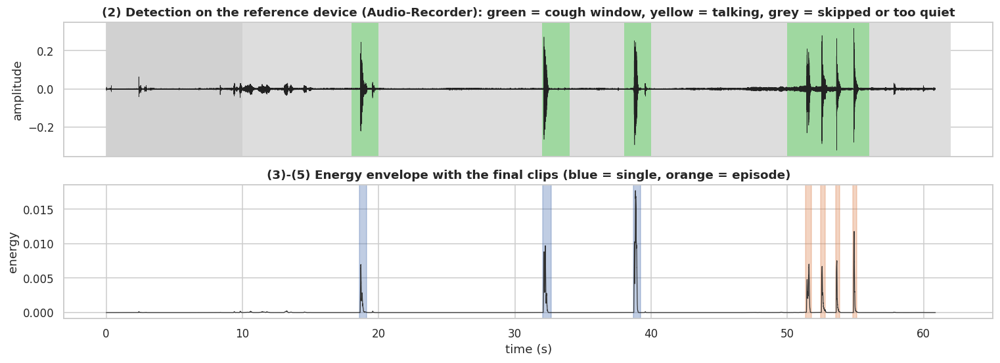

Clips per device: 7 | alignment scores: {'Audio-Recorder': 1.0, 'Phone A': 0.501, 'Phone B': 0.491, 'Phone C': 0.529}


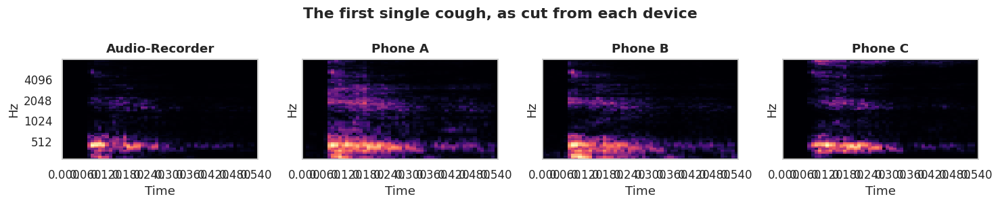

In [19]:
ex_site = files.loc[files.subject_id == EXAMPLE_ID, "site"].iloc[0]
ex_rows, ex_info, dbg = segment_subject(EXAMPLE_ID, ex_site, DETECTOR, write=False)
ref, t = dbg["aligned"][0], np.arange(len(dbg["aligned"][0])) / SR
colors = {-1: "#DDDDDD", 0: "#F5F5F5", 1: "#FFE29A", 2: "#9FD8A0"}
fig, axes = plt.subplots(2, 1, figsize=(14, 5.2), sharex=True)
for i, lab_i in enumerate(dbg["raw"]):
    axes[0].axvspan(i * WIN_S, (i + 1) * WIN_S, color=colors[dbg["final"][i] if dbg["final"][i] == 2 else lab_i], lw=0)
axes[0].axvspan(0, (int(SKIP_S / WIN_S) + 1) * WIN_S, color="#BBBBBB", alpha=0.35, lw=0)
axes[0].plot(t, ref, lw=0.4, color="#222222")
axes[0].set(title=f"(2) Detection on the reference device ({dbg['devices'][0]}): green = cough window, "
                  "yellow = talking, grey = skipped or too quiet", ylabel="amplitude")
env = energy_envelope(ref)
axes[1].plot(t, env, lw=0.8, color="#333333")
for s, e, *_ in dbg["singles"]:
    axes[1].axvspan(s / SR, e / SR, color="#4C72B0", alpha=0.35)
for s, e, *_ in dbg["seq"]:
    axes[1].axvspan(s / SR, e / SR, color="#DD8452", alpha=0.35)
axes[1].set(title="(3)-(5) Energy envelope with the final clips (blue = single, orange = episode)",
            xlabel="time (s)", ylabel="energy")
plt.tight_layout(); plt.show()
print(f"Clips per device: {ex_info['n_clips_per_device']} | alignment scores:",
      {k.replace('align_score_', ''): v for k, v in ex_info.items() if k.startswith("align_score")})

if dbg["singles"]:
    s, e, *_ = dbg["singles"][0]
    fig, axes = plt.subplots(1, len(dbg["devices"]), figsize=(3.4 * len(dbg["devices"]), 2.8), sharey=True)
    for ax, d, y in zip(np.atleast_1d(axes), dbg["devices"], dbg["aligned"]):
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=y[s:e], sr=SR, n_fft=400, hop_length=160,
                                n_mels=64, fmin=100, fmax=8000) + 1e-2, ref=np.max)
        librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="mel", fmin=100, fmax=8000,
                                 ax=ax, cmap="magma")
        ax.set_title(d)
    fig.suptitle("The first single cough, as cut from each device", fontweight="bold")
    plt.tight_layout(); plt.show()

### Step 6b. Run the extractor on every participant

This is the slow step (roughly 45 to 90 minutes on the real data). Progress is saved every 20 participants, so if the session stops, run the cell again and it continues where it left off. The output is:

* `segmented_coughs/<device>_<site>/<participant>_<k>.wav`: one file per cough per device (same naming as Zhang et al.);
* `outputs/segmentation_manifest.csv`: one row per clip (participant, device, cough number, type, times, duration);
* `outputs/segmentation_qc.csv`: one row per participant (alignment scores, number of cough windows, any errors).

In [20]:
MANIFEST_PATH, QC_PATH = OUT / "segmentation_manifest.csv", OUT / "segmentation_qc.csv"
SEG_ROOT = SEG_DIR

if CFG["SEGMENTED_INPUT"]:
    root = restore_input(CFG["SEGMENTED_INPUT"], "segmentation_manifest.csv", "segmented_coughs")
    MANIFEST_PATH, QC_PATH = root / "segmentation_manifest.csv", root / "segmentation_qc.csv"
    SEG_ROOT = root / "segmented_coughs"
    if not SEG_ROOT.is_dir():   # a plain copy of /kaggle/working: outputs/ and segmented_coughs/ side by side
        SEG_ROOT = next(p for p in Path(CFG["SEGMENTED_INPUT"]).rglob("segmented_coughs") if p.is_dir())
    print("Using previously segmented coughs from", SEG_ROOT)
elif CFG["RUN_SEGMENTATION"]:
    try:
        from tqdm.auto import tqdm
    except ImportError:
        tqdm = lambda x, **k: x
    done = set(pd.read_csv(QC_PATH).subject_id) if QC_PATH.exists() else set()
    todo = sorted(set(files.loc[files.site.isin(CFG["SEGMENT_SITES"]), "subject_id"]) - done)
    print(f"{len(done)} participants already done, {len(todo)} to go")
    buf_rows, buf_info, t0 = [], [], time.time()
    # Fixed column order for every write. Without it, a batch whose participants lack a device
    # (e.g. no recorder) writes its values in a different order under the first batch's header.
    MANIFEST_COLUMNS = ["subject_id", "site", "device", "clip_idx", "cough_type", "start_s", "end_s",
                        "dur_s", "spans_join", "rel_path"]
    QC_COLUMNS = (["subject_id", "site", "reference", "n_devices", "session_s", "n_cough_windows",
                   "error_single", "error_sequence"]
                  + [f"{kind}_{d}" for d in DEVICE_ORDER for kind in ("lag_s", "align_score")]
                  + ["n_clips_per_device"])
    def flush():
        global buf_rows, buf_info
        if buf_rows:
            pd.DataFrame(buf_rows).reindex(columns=MANIFEST_COLUMNS).to_csv(
                MANIFEST_PATH, mode="a", header=not MANIFEST_PATH.exists(), index=False)
        if buf_info:
            pd.DataFrame(buf_info).reindex(columns=QC_COLUMNS).to_csv(
                QC_PATH, mode="a", header=not QC_PATH.exists(), index=False)
        buf_rows, buf_info = [], []
    for n, sid in enumerate(tqdm(todo, desc="segmenting"), 1):
        site = files.loc[files.subject_id == sid, "site"].iloc[0]
        try:
            r, info, _ = segment_subject(sid, site, DETECTOR)
        except Exception as exc:
            r, info = [], dict(subject_id=sid, site=site, error_single=f"FAILED: {exc!r}")
        buf_rows += r; buf_info.append(info)
        if n % 20 == 0:
            flush()
    flush()
    print(f"Segmentation finished in {(time.time() - t0) / 60:.1f} min")

assert MANIFEST_PATH.exists(), "No segmentation found: set RUN_SEGMENTATION = True or point SEGMENTED_INPUT to an earlier run."
manifest = pd.read_csv(MANIFEST_PATH).drop_duplicates(["subject_id", "device", "clip_idx"], keep="last")
seg_qc = pd.read_csv(QC_PATH).drop_duplicates("subject_id", keep="last")
print(f"{len(manifest)} clips from {manifest.subject_id.nunique()} participants")

0 participants already done, 363 to go


segmenting:   0%|          | 0/363 [00:00<?, ?it/s]

Segmentation finished in 12.1 min
7314 clips from 359 participants


### Step 6c. Quality checks on the segmentation

**What to look for.**
* **Clips per participant:** usually 3 singles plus a handful from the episode. Participants with zero clips should be few.
* **Clip length:** all below 1 second by construction; a pile-up near 1 s would mean many merged coughs.
* **Alignment score:** most sessions near the top of the range. A device scoring far below the others for the same participant suggests a wrong file (a mislabel the log missed) or a failed recording. These are listed and saved to `outputs/suspect_alignment.csv`; listen to a few.
* **Episode clips crossing an artificial join:** should be rare.

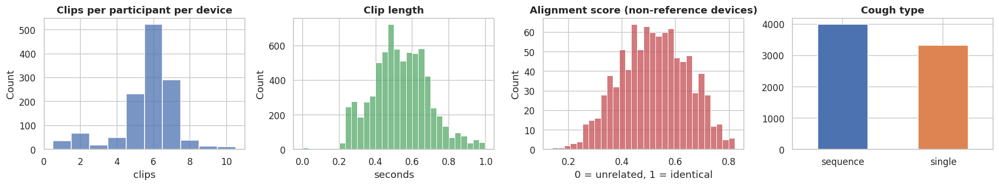

Participants with zero clips: 4 of 363
Episode clips crossing an artificial join: 0 of 3991
Participants with an extraction error: 36
Lowest 2% alignment scores (<= 0.268) saved for listening:


,subject_id,device,score
1029,02-399-0781,Phone B,0.138
1178,01-399-0895,Phone C,0.167
1125,01-399-0839,Phone C,0.197
714,03-399-0321,Phone A,0.200
703,03-399-0310,Phone A,0.210
1160,01-399-0876,Phone C,0.218
1392,02-399-0781,Phone C,0.229
1061,03-399-0304,Phone B,0.230
1171,01-399-0888,Phone C,0.245
1446,03-399-0328,Phone C,0.245


In [21]:
per = manifest.groupby(["subject_id", "device"]).size().rename("clips").reset_index()
score_cols = [c for c in seg_qc.columns if c.startswith("align_score_")]
long_scores = seg_qc.melt(id_vars=["subject_id"], value_vars=score_cols, var_name="device",
                          value_name="score").dropna()
long_scores["device"] = long_scores.device.str.replace("align_score_", "", regex=False)
long_scores = long_scores[long_scores.score < 0.999]          # the reference itself scores 1

fig, axes = plt.subplots(1, 4, figsize=(17, 3.3))
sns.histplot(per.clips, discrete=True, ax=axes[0], color="#4C72B0")
axes[0].set(title="Clips per participant per device", xlabel="clips")
sns.histplot(manifest.dur_s, bins=30, ax=axes[1], color="#55A868")
axes[1].set(title="Clip length", xlabel="seconds")
sns.histplot(long_scores.score, bins=30, ax=axes[2], color="#C44E52")
axes[2].set(title="Alignment score (non-reference devices)", xlabel="0 = unrelated, 1 = identical")
manifest.cough_type.value_counts().plot.bar(ax=axes[3], color=["#4C72B0", "#DD8452"])
axes[3].set(title="Cough type", xlabel=""); plt.setp(axes[3].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

no_clips = sorted(set(seg_qc.subject_id) - set(manifest.subject_id))
print(f"Participants with zero clips: {len(no_clips)} of {seg_qc.subject_id.nunique()}")
print(f"Episode clips crossing an artificial join: {int(manifest.spans_join.sum())} of "
      f"{int((manifest.cough_type == 'sequence').sum())}")
errs = seg_qc[(seg_qc.error_single.fillna("") != "") | (seg_qc.error_sequence.fillna("") != "")]
print(f"Participants with an extraction error: {len(errs)}")
thr = long_scores.score.quantile(0.02)
suspect = long_scores[long_scores.score <= thr].sort_values("score")
suspect.to_csv(OUT / "suspect_alignment.csv", index=False)
print(f"Lowest 2% alignment scores (<= {thr:.3f}) saved for listening:")
display(suspect.head(10))

In [22]:
# Save the segmentation now, so a later crash cannot cost us the slowest step
if CFG["EXPORT"] and not CFG["SEGMENTED_INPUT"]:
    export_bundle("zambia_segmented_coughs", {
        "segmented_coughs": SEG_ROOT,
        "segmentation_manifest.csv": MANIFEST_PATH,
        "segmentation_qc.csv": QC_PATH,
        "suspect_alignment.csv": OUT / "suspect_alignment.csv",
        "audit_files.csv": OUT / "audit_files.csv",
    }, "Cough clips cut from the Zambia CIDRZ sessions with Zhang et al.'s extractor. Clip k of a participant "
       "is the same cough on every device. To reuse, set CFG['SEGMENTED_INPUT'] to the folder holding this zip.")

Saved zambia_segmented_coughs.zip: 127.0 MB, 7318 files, in 3 s


### Step 6d. Do the devices sound different? (device signatures)

**What we do.** Average the frequency content of every clip, separately per device.

**Why.** Zhang et al. found that models learn *which device* recorded a cough more readily than *whether the person has TB*. If the devices have visibly different frequency responses, that explanation is plausible here too.

**What to look for.** Curves that separate at higher frequencies, typically the lower-tier phone losing energy earlier. The second figure shows one cough on each phone side by side.

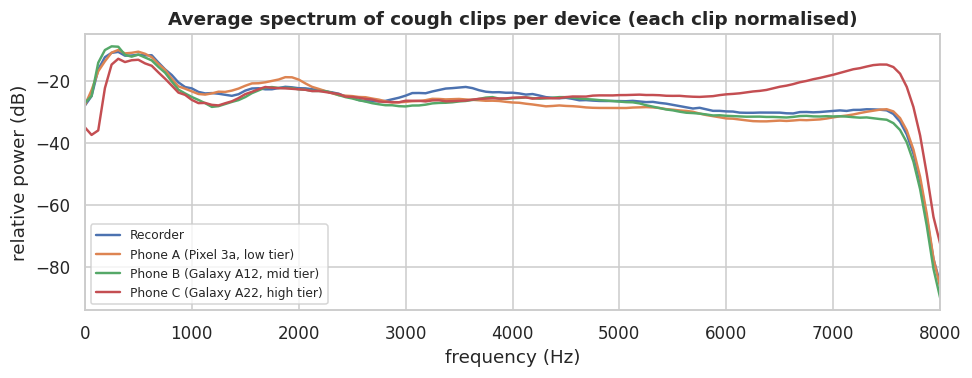

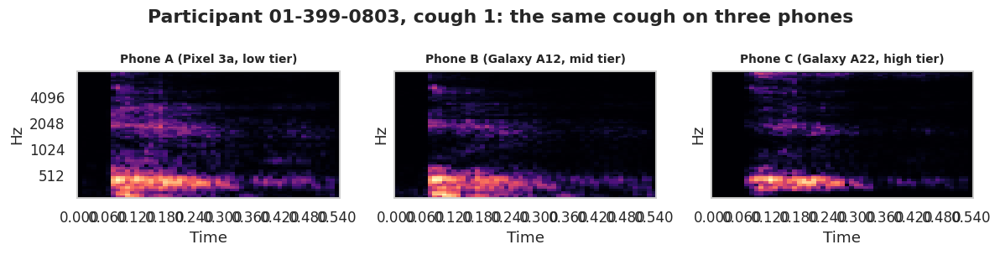

In [23]:
rng_vis = np.random.default_rng(CFG["SEED"])
fig, ax = plt.subplots(figsize=(9, 3.6))
for dev in DEVICE_ORDER:
    sub = manifest[manifest.device == dev]
    if sub.empty:
        continue
    pick = sub.sample(min(400, len(sub)), random_state=CFG["SEED"])
    psds = []
    for rel in pick.rel_path:
        y, _ = sf.read(SEG_ROOT / rel, dtype="float32")
        if len(y) >= 256:
            f, p = welch(y, fs=SR, nperseg=256)
            psds.append(p / (p.sum() + 1e-12))
    if psds:
        ax.plot(f, 10 * np.log10(np.mean(psds, axis=0) + 1e-12), label=DEVICE_LABEL[dev], lw=1.6)
ax.set(title="Average spectrum of cough clips per device (each clip normalised)", xlabel="frequency (Hz)",
       ylabel="relative power (dB)", xlim=(0, 8000))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

phones = ["Phone A", "Phone B", "Phone C"]
trip = manifest[manifest.device.isin(phones)].groupby(["subject_id", "clip_idx"]).device.nunique()
if (trip == 3).any():
    sid, k = trip[trip == 3].index[0]
    fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
    for ax, dev in zip(axes, phones):
        rel = manifest[(manifest.subject_id == sid) & (manifest.clip_idx == k) & (manifest.device == dev)].rel_path.iloc[0]
        y, _ = sf.read(SEG_ROOT / rel, dtype="float32")
        S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_fft=400, hop_length=160, n_mels=64,
                                fmin=100, fmax=8000) + 1e-2, ref=np.max)
        librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="mel", fmin=100, fmax=8000,
                                 ax=ax, cmap="magma")
        ax.set_title(DEVICE_LABEL[dev], fontsize=9)
    fig.suptitle(f"Participant {sid}, cough {k}: the same cough on three phones", fontweight="bold")
    plt.tight_layout(); plt.show()

## Step 7. Define the analysis cohort

**What we do.** Keep the clips Zhang et al. used for their within-Zambia result: **Chawama and Kanyama only** (Chainda-South had a single TB-positive participant), **Phones A, B and C only** (the recorder covered too few people and is kept aside), and only participants with a TB label.

We also define a second, stricter group for Notebook 02: the **paired cohort**, participants with at least one clip on *each* of the three phones.

**What to look for.** Counts close to Zhang et al.'s published table (shown alongside). Small differences are expected, since segmentation and relabeling details differ slightly; large ones mean something went wrong upstream. Note the number of TB-positive participants per phone: it sets how precise any AUROC can be.

In [24]:
labels = clin.set_index("subject_id").label
manifest["label"] = manifest.subject_id.map(labels)
coh = manifest[manifest.site.isin(CFG["COHORT_SITES"]) & manifest.device.isin(CFG["COHORT_DEVICES"])
               & manifest.label.notna()].copy()
coh["label"] = coh.label.astype(int)
coh = coh.sort_values(["subject_id", "device", "clip_idx"]).reset_index(drop=True)
coh["clip_id"] = np.arange(len(coh))

subj = coh.groupby("subject_id").agg(site=("site", "first"), label=("label", "first"),
                                     n_phones=("device", "nunique"), n_clips=("clip_id", "size"))
paired_ids = sorted(subj.index[subj.n_phones == 3])

ZHANG_TABLE = {("Chawama", "Phone A"): (111, 687, 9), ("Chawama", "Phone B"): (102, 595, 10),
               ("Chawama", "Phone C"): (109, 635, 9), ("Kanyama", "Phone A"): (207, 1158, 22),
               ("Kanyama", "Phone B"): (214, 1229, 22), ("Kanyama", "Phone C"): (214, 1205, 22)}
rows = []
for (site, dev), g in coh.groupby(["site", "device"]):
    s = g.groupby("subject_id").label.first()
    z = ZHANG_TABLE.get((site, dev), (np.nan,) * 3)
    rows.append(dict(site=site, device=dev, participants=len(s), clips=len(g), tb_pos=int(s.sum()),
                     tb_rate_pct=round(100 * s.mean(), 1), zhang_participants=z[0], zhang_clips=z[1],
                     zhang_tb_rate_pct=z[2]))
cohort_table = pd.DataFrame(rows)
display(cohort_table)
print(f"Reproduction cohort: {len(subj)} participants ({int(subj.label.sum())} TB+), {len(coh)} clips")
print(f"Paired cohort (all three phones): {len(paired_ids)} participants "
      f"({int(subj.loc[paired_ids].label.sum())} TB+)")

subj.to_csv(OUT / "cohort_reproduction.csv")
pd.Series(paired_ids, name="subject_id").to_csv(OUT / "cohort_paired.csv", index=False)

,site,device,participants,clips,tb_pos,tb_rate_pct,zhang_participants,zhang_clips,zhang_tb_rate_pct
0,Chawama,Phone A,108,632,10,9.3,111,687,9
1,Chawama,Phone B,101,589,10,9.9,102,595,10
2,Chawama,Phone C,108,629,10,9.3,109,635,9
3,Kanyama,Phone A,206,1117,45,21.8,207,1158,22
4,Kanyama,Phone B,212,1155,47,22.2,214,1229,22
5,Kanyama,Phone C,213,1165,47,22.1,214,1205,22


Reproduction cohort: 325 participants (57 TB+), 5287 clips
Paired cohort (all three phones): 299 participants (55 TB+)


## Step 8. Shared cross-validation folds

**What we do.** Split *participants* (never individual clips) into 5 groups, balanced by site and TB status. Each group takes a turn as the test set while the model learns from the other four. In the full run this is repeated twice with different shuffles, giving 10 test sets (Zhang et al.'s protocol).

**Why participants, not clips.** One person contributes many coughs. If some of their coughs are in training and others in testing, the model can recognise the *person* rather than the disease, and results look better than they are.

**Why shared.** Every model in this project, clinical or audio, is evaluated on exactly these test sets. That makes the comparisons *paired*: the same people, scored by two models, so differences reflect the models and not the luck of the split.

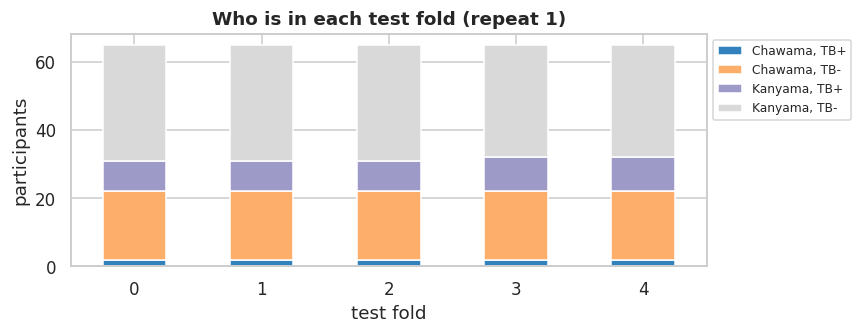

In [25]:
strata = subj.site + "_" + subj.label.astype(str)
rep_seeds = np.random.RandomState(CFG["SEED"]).randint(0, 100, CFG["N_REPEATS"])
fold_rows = []
for r, seed in enumerate(rep_seeds):
    skf = StratifiedKFold(CFG["N_OUTER"], shuffle=True, random_state=int(seed))
    for k, (_, te) in enumerate(skf.split(subj.index, strata)):
        fold_rows += [dict(repeat=r, fold=k, subject_id=s) for s in subj.index[te]]
folds = pd.DataFrame(fold_rows)
folds.to_csv(OUT / "folds.csv", index=False)

comp = folds[folds.repeat == 0].merge(subj[["site", "label"]], left_on="subject_id", right_index=True)
comp["group"] = comp.site + ", " + comp.label.map({0: "TB-", 1: "TB+"})
ct = pd.crosstab(comp.fold, comp.group)
ax = ct.plot.bar(stacked=True, figsize=(8, 3.2), colormap="tab20c")
ax.set(title="Who is in each test fold (repeat 1)", xlabel="test fold", ylabel="participants")
plt.setp(ax.get_xticklabels(), rotation=0); ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

def inner_splits(train_ids, r, k, n_inner):
    s = strata.loc[train_ids]
    skf = StratifiedKFold(n_inner, shuffle=True, random_state=1000 * r + k)
    return [(train_ids[a], train_ids[b]) for a, b in skf.split(train_ids, s)]

In [26]:
# Save the cleaned metadata, cohorts and the shared folds
if CFG["EXPORT"]:
    inv = files.copy()
    inv["rel_path_in_dataset"] = [str(Path(p).relative_to(DATA_ROOT)) for p in inv.path]
    export_bundle("zambia_metadata_cohort", {
        "clinical_harmonised.csv": clin,
        "metadata_column_profile.csv": profile,
        "relabel_log_applied.csv": log,
        "audio_file_inventory.csv": inv.drop(columns=["path"]),
        "device_coverage.csv": coverage,
        "cohort_table.csv": cohort_table,
        "cohort_reproduction.csv": subj,
        "cohort_paired.csv": pd.DataFrame({"subject_id": paired_ids}),
        "folds.csv": folds,
        "audit_files.csv": OUT / "audit_files.csv",
        "audit_participants.csv": OUT / "audit_participants.csv",
        "audit_pairs.csv": OUT / "audit_pairs.csv",
        "audit_suggested_relabels.csv": OUT / "audit_suggested_relabels.csv",
    }, "Cleaned participant data (the 9 clinical variables mapped exactly as Zhang et al.), the audio file "
       "inventory after relabeling, both cohorts, and the shared participant-level folds. Reuse folds.csv "
       "unchanged in every later notebook so all comparisons stay paired.")

Saved zambia_metadata_cohort.zip: 0.1 MB, 13 files, in 0 s


## Step 9. Baseline B: clinical variables only

**What we do.** A logistic regression on the nine questionnaire variables (age, sex, smoking, HIV, previous TB, cough duration, fever, weight loss, night sweats), tuned exactly as Zhang et al. did: a grid over the regularisation strength `C` (and `max_iter`), chosen by 4-fold cross-validation inside the training data only.

**Why.** This is the yardstick. In triage, these answers cost nothing to collect, so cough audio only earns its place if it adds to them.

**Two versions.**
* **B (cohort):** on the participants in our audio cohort, scored on the shared folds. This is the one we compare audio against.
* **B (all participants):** on all ~1,823 participants with complete answers, to check we reproduce Zhang et al.'s 0.767 ± 0.025.

**One small change.** Zhang et al. standardised age and cough duration using statistics from all data before splitting. We do it inside each training fold, so test participants never influence the scaling.

B (cohort): AUROC 0.749 ± 0.094 over 10 test folds | 0 cohort participants dropped for missing answers
B (all 1823 participants): AUROC 0.759 ± 0.029 | Zhang et al.: 0.767 ± 0.025


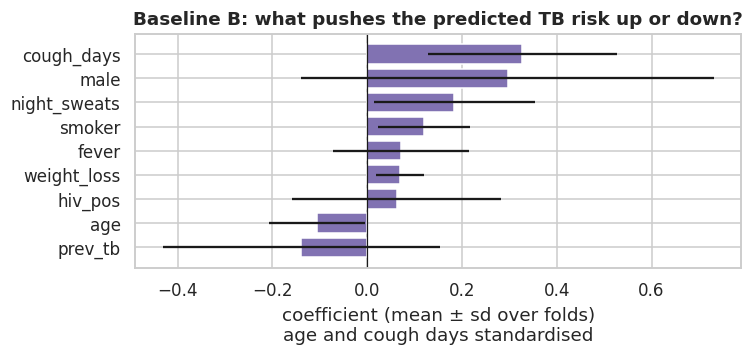

In [27]:
def fit_clinical(X, y, seed):
    pre = ColumnTransformer([("num", StandardScaler(), CLIN_CONTINUOUS)], remainder="passthrough")
    pipe = Pipeline([("pre", pre), ("lr", LogisticRegression())])
    grid = {"lr__C": [0.01, 0.1, 1, 10, 100], "lr__max_iter": [100, 500, 1000]}   # Zhang et al.
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", n_jobs=-1,
                      cv=StratifiedKFold(4, shuffle=True, random_state=seed))
    gs.fit(X, y)
    return gs.best_estimator_

def coef_table(model):
    names = [n.split("__", 1)[1] for n in model.named_steps["pre"].get_feature_names_out()]
    return pd.Series(model.named_steps["lr"].coef_.ravel(), index=names)

def fold_auc_table(df, score="score"):
    out = []
    for (r, k), g in df.groupby(["repeat", "fold"]):
        if g.label.nunique() == 2:
            out.append(dict(repeat=r, fold=k, auroc=roc_auc_score(g.label, g[score])))
    return pd.DataFrame(out)

def spec_at_sens(y, s, target=0.90):
    fpr, tpr, _ = roc_curve(y, s)
    return float(1 - fpr[np.argmax(tpr >= target)])

def boot_auc_ci(y, s, n_boot=2000, seed=0):
    rng, y, s = np.random.default_rng(seed), np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            vals.append(roc_auc_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

complete_ids = set(clin.dropna(subset=CLIN_FEATURES + ["label"]).subject_id)
cdat = clin.set_index("subject_id")
b_rows, b_coefs = [], []
for (r, k), te in folds.groupby(["repeat", "fold"]):
    test_ids = [s for s in te.subject_id if s in complete_ids]
    train_ids = [s for s in subj.index if s not in set(te.subject_id) and s in complete_ids]
    m = fit_clinical(cdat.loc[train_ids, CLIN_FEATURES], cdat.loc[train_ids, "label"].astype(int), seed=r * 10 + k)
    p = m.predict_proba(cdat.loc[test_ids, CLIN_FEATURES])[:, 1]
    b_rows += [dict(repeat=r, fold=k, subject_id=s, label=int(cdat.loc[s, "label"]), score=v)
               for s, v in zip(test_ids, p)]
    b_coefs.append(coef_table(m))
clin_oof = pd.DataFrame(b_rows)
clin_oof.to_csv(OUT / "clinical_oof.csv", index=False)
b_folds = fold_auc_table(clin_oof)
dropped = len(subj) - len(set(subj.index) & complete_ids)
print(f"B (cohort): AUROC {b_folds.auroc.mean():.3f} ± {b_folds.auroc.std(ddof=0):.3f} over "
      f"{len(b_folds)} test folds | {dropped} cohort participants dropped for missing answers")

# B on all participants, Zhang et al. setup (single 5-fold split, seed 42)
full = cdat.loc[sorted(complete_ids)]
skf = StratifiedKFold(5, shuffle=True, random_state=CFG["SEED"])
full_auc = []
for tr, te in skf.split(full, full.label):
    m = fit_clinical(full.iloc[tr][CLIN_FEATURES], full.iloc[tr].label.astype(int), seed=CFG["SEED"])
    full_auc.append(roc_auc_score(full.iloc[te].label, m.predict_proba(full.iloc[te][CLIN_FEATURES])[:, 1]))
print(f"B (all {len(full)} participants): AUROC {np.mean(full_auc):.3f} ± {np.std(full_auc):.3f} "
      f"| Zhang et al.: 0.767 ± 0.025")

co = pd.concat(b_coefs, axis=1)
fig, ax = plt.subplots(figsize=(7, 3.4))
order = co.mean(axis=1).sort_values().index
ax.barh(order, co.loc[order].mean(axis=1), xerr=co.loc[order].std(axis=1), color="#8172B2")
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Baseline B: what pushes the predicted TB risk up or down?",
       xlabel="coefficient (mean ± sd over folds)\nage and cough days standardised")
plt.tight_layout(); plt.show()

## Step 10. Baseline C1: VGGish on mel spectrograms (audio only)

### 10.1 From a cough to a picture: the mel spectrogram

**What we do.** Turn each clip into a mel spectrogram: a small image whose horizontal axis is time, vertical axis is pitch on a scale close to human hearing, and brightness is loudness. Settings follow Zhang et al. exactly: 25 ms windows every 10 ms, 64 mel bands from 100 to 8,000 Hz, loudness in decibels relative to the clip's loudest point, and every clip made exactly 0.96 s long by repeating it if shorter.

**Why 0.96 s and 64 bands.** That is the input size VGGish was originally trained with.

**Training-only extras.**
* **Balancing:** clips are oversampled so every combination of phone, site and TB status is equally common. Otherwise the model could learn "Kanyama means more TB" (Kanyama's prevalence is about twice Chawama's).
* **Augmentation:** each oversampled copy is altered slightly (pitch shift, small speed wobbles, added noise), so repeated copies are not identical.

**Our change.** Zhang et al. built the balanced, augmented set *before* splitting, so their test clips were also augmented and duplicated. We augment training clips only and **test on the clean clips**, which is standard practice.

Clean test clips: (5287, 1, 64, 97) | balanced augmented training pool: (11004, 1, 64, 97)
Training pool composition (phone x site x TB):


label              0    1
device  site             
Phone A Chawama  917  917
        Kanyama  917  917
Phone B Chawama  917  917
        Kanyama  917  917
Phone C Chawama  917  917
        Kanyama  917  917

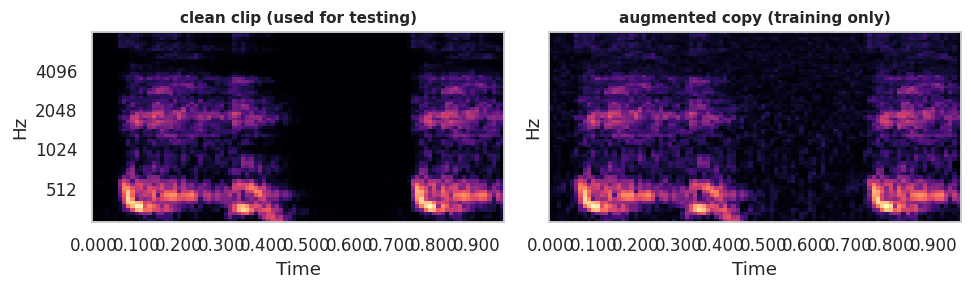

In [28]:
MEL = dict(n_fft=int(0.025 * SR), hop_length=int(0.010 * SR), n_mels=64, fmin=100, fmax=8000)
AUDIO_DURATION = 0.96

def pad_or_crop(y, rng):
    n = int(AUDIO_DURATION * SR)
    if len(y) < n:
        return np.tile(y, int(np.ceil(n / max(len(y), 1))))[:n]
    start = int(rng.integers(0, len(y) - n + 1))
    return y[start:start + n]

def mel_db(y):
    m = librosa.feature.melspectrogram(y=y, sr=SR, **MEL)
    return librosa.power_to_db(m + 1e-2, ref=np.max)[None].astype(np.float32)   # [1, 64, 97]

# ---- augmentations (Zhang et al., utils_audio_aug.py, MIT licence) ----
def aug_add_noise(y, snr_db=10.0, p_apply=1.0):
    if random.random() > p_apply: return y
    rms = np.sqrt(np.mean(y ** 2)) + 1e-12
    return y + np.random.normal(0, rms / 10 ** (snr_db / 20.0), len(y))

def aug_brownian_tape_speed(y, max_rate_perturb=0.1, n_walk_steps=5, p_apply=0.8):
    if random.random() > p_apply or n_walk_steps <= 1: return y
    edges = np.linspace(0, len(y), n_walk_steps + 1, dtype=int)
    segs = []
    for i in range(n_walk_steps):
        seg = y[edges[i]:edges[i + 1]]
        if len(seg) < 2: continue
        f = 1.0 + np.random.uniform(-max_rate_perturb, max_rate_perturb)
        segs.append(librosa.resample(seg.astype(float), orig_sr=SR, target_sr=int(SR * f)))
    return np.concatenate(segs) if segs else y

def aug_pitch_shift(y, max_steps=4.0, p_apply=1.0):
    if random.random() > p_apply: return y
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=np.random.uniform(-max_steps, max_steps))

AUG_OPTIONS = [[aug_pitch_shift, aug_brownian_tape_speed], [aug_pitch_shift, aug_add_noise],
               [aug_pitch_shift], [aug_brownian_tape_speed], [aug_add_noise]]

def augment(y):
    for f in AUG_OPTIONS[np.random.choice(len(AUG_OPTIONS))]:
        y = f(y)
    return y.astype(np.float32)

def read_clip(rel):
    y, sr = sf.read(SEG_ROOT / rel, dtype="float32")
    return librosa.resample(y, orig_sr=sr, target_sr=SR) if sr != SR else y

import hashlib
sig = hashlib.md5(("|".join(coh.rel_path) + json.dumps(MEL) + f"{AUDIO_DURATION}_{CFG['SEED']}").encode()).hexdigest()[:12]
clean_file, pool_file = CACHE / f"clean_X_{sig}.npy", CACHE / f"pool_{sig}.npz"
FEATURES_RESTORED = False
if CFG.get("FEATURES_INPUT"):
    fdir = restore_input(CFG["FEATURES_INPUT"], "feature_settings.json", "features")
    if (fdir / clean_file.name).exists() and (fdir / pool_file.name).exists():
        clean_file, pool_file, FEATURES_RESTORED = fdir / clean_file.name, fdir / pool_file.name, True
        print("Using previously computed features from", fdir)
    else:
        print("FEATURES_INPUT was built from different clips than this cohort, so features are recomputed.")

if clean_file.exists():
    clean_X = np.load(clean_file)
else:
    rng = np.random.default_rng(CFG["SEED"])
    clean_X = np.stack([mel_db(pad_or_crop(read_clip(r), rng)) for r in coh.rel_path])
    np.save(clean_file, clean_X)

if pool_file.exists():
    d = np.load(pool_file); pool_X, pool_clip = d["X"], d["clip_id"]
else:
    sg = coh.device + "_" + coh.site + "_" + coh.label.astype(str)
    max_n = sg.value_counts().max()
    seeds = np.random.default_rng(CFG["SEED"]).integers(0, 10_000, sg.nunique())
    audio_cache, Xs, ids = {}, [], []
    for g, seed in zip(sorted(sg.unique()), seeds):
        pos = np.where(sg.values == g)[0]
        np.random.seed(int(seed)); random.seed(int(seed))
        sel = np.concatenate([np.arange(len(pos)), np.random.choice(len(pos), max_n - len(pos), replace=True)]) \
            if len(pos) < max_n else np.arange(max_n)
        for o in sel:
            i = pos[o]
            if i not in audio_cache:
                audio_cache[i] = read_clip(coh.rel_path.iloc[i])
            Xs.append(mel_db(pad_or_crop(augment(audio_cache[i]), np.random.default_rng(int(seed) + int(o)))))
            ids.append(int(coh.clip_id.iloc[i]))
    pool_X, pool_clip = np.stack(Xs), np.array(ids)
    np.savez(pool_file, X=pool_X, clip_id=pool_clip)

pool_meta = coh.set_index("clip_id").loc[pool_clip, ["subject_id", "device", "site", "label"]].reset_index()
print(f"Clean test clips: {clean_X.shape} | balanced augmented training pool: {pool_X.shape}")
print("Training pool composition (phone x site x TB):")
display(pool_meta.groupby(["device", "site", "label"]).size().unstack())

i0 = int(np.where(pool_clip == coh.clip_id.iloc[0])[0][0])
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, img, title in zip(axes, [clean_X[0, 0], pool_X[i0, 0]], ["clean clip (used for testing)", "augmented copy (training only)"]):
    librosa.display.specshow(img, sr=SR, hop_length=MEL["hop_length"], x_axis="time", y_axis="mel",
                             fmin=100, fmax=8000, ax=ax, cmap="magma")
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

In [29]:
# Save the features (only when they were computed in this run, not restored from a bundle)
if CFG["EXPORT"] and not FEATURES_RESTORED:
    export_bundle("zambia_features_mel", {
        clean_file.name: clean_file,
        pool_file.name: pool_file,
        "clean_index.csv": coh[["clip_id", "subject_id", "site", "device", "label", "clip_idx",
                                "cough_type", "rel_path"]],
        "pool_index.csv": pool_meta,
        "feature_settings.json": dict(
            signature=sig, mel=MEL, audio_duration_s=AUDIO_DURATION, sample_rate=SR, seed=CFG["SEED"],
            clean_shape=list(clean_X.shape), pool_shape=list(pool_X.shape),
            notes="clean_X row i = clean_index row i (test/validation clips, no augmentation). "
                  "pool rows = pool_index rows (training only: balanced by phone x site x TB, augmented)."),
    }, "Mel-spectrogram features for Baseline C1: clean clips (for testing) and the balanced, augmented "
       "training pool, with indexes linking every row to a participant, phone and cough.")

Saved zambia_features_mel.zip: 404.7 MB, 5 files, in 2 s


### 10.2 The model and the training recipe

**VGGish** is a convolutional network Google trained on millions of YouTube sound clips. We start from those weights and fine-tune the whole network on our coughs, with a small head on top (128 → 16 → 1) that outputs a TB score.

**Recipe (Zhang et al.):** Adam optimiser, learning rate 1e-4 for VGGish and 1e-5 for the head, batch size 32, up to 40 epochs, mixup (blending pairs of examples) with α = 0.1, class-weighted loss, learning rate halved when validation stalls, and early stopping after 5 epochs without improvement in validation AUROC.

**Per test fold:** the training participants are split into 4 inner folds; 4 models are trained, each validated on a different inner fold. Each test clip is scored by all 4 models, and a participant's score is the **median over all their clips and all 4 models** (as in Zhang et al.'s code).

**Two bugs in the original code that we fix (please mention these when comparing numbers):**
1. **Weight loading.** The original copies pretrained tensors into the model by *matching shapes*. Several layers share a bias shape, so 4 bias vectors stay random and 4 others receive another layer's bias. We load by *name* and check all 18 tensors match.
2. **Early stopping.** The original saves the "best" weights with `model.state_dict()` without copying. In PyTorch that dictionary points at the live weights, so restoring it restores the *current* weights, not the best ones. We save a real copy.

Both fixes should help slightly, so do not expect our number to equal 0.755 exactly.

**The `smoke` backend.** Setting `AUDIO_BACKEND = "smoke"` replaces VGGish with a logistic regression on the average of each spectrogram. It is not a result; it exists so the full pipeline can be checked in a couple of minutes.

In [30]:
if TORCH_OK:
    import torch.nn as nn
    from torchvision import transforms

    VGGISH_URL = "https://github.com/harritaylor/torchvggish/releases/download/v0.1/vggish-10086976.pth"

    class VGGishBackbone(nn.Module):
        # Same layout as torchvggish, so checkpoint names match exactly (features.*, embeddings.*).
        def __init__(self):
            super().__init__()
            def conv(cin, cout):
                return [nn.Conv2d(cin, cout, 3, 1, 1), nn.ReLU(inplace=True)]
            self.features = nn.Sequential(
                *conv(1, 64), nn.MaxPool2d(2, 2), *conv(64, 128), nn.MaxPool2d(2, 2),
                *conv(128, 256), *conv(256, 256), nn.MaxPool2d(2, 2),
                *conv(256, 512), *conv(512, 512), nn.MaxPool2d(2, 2))
            self.embeddings = nn.Sequential(
                nn.Linear(512 * 24, 4096), nn.ReLU(True), nn.Linear(4096, 4096), nn.ReLU(True),
                nn.Linear(4096, 128), nn.ReLU(True))
        def forward(self, x):
            x = self.features(x).permute(0, 2, 3, 1).contiguous()
            return self.embeddings(x.view(x.size(0), -1))

    _VGGISH_SD = None
    def vggish_weights():
        global _VGGISH_SD
        if _VGGISH_SD is None:
            path = CACHE / "vggish-10086976.pth"
            if not path.exists():
                torch.hub.download_url_to_file(VGGISH_URL, str(path), hash_prefix="10086976")
            try:
                _VGGISH_SD = torch.load(path, map_location="cpu", weights_only=True)
            except TypeError:
                _VGGISH_SD = torch.load(path, map_location="cpu")
        return _VGGISH_SD

    def build_vggish():
        backbone = VGGishBackbone()
        backbone.load_state_dict(vggish_weights(), strict=True)     # by name: fails loudly on mismatch
        head = nn.Sequential(nn.Linear(128, 16), nn.ReLU(), nn.Dropout(0.5), nn.Linear(16, 1))
        return nn.Sequential(backbone, head)

    RESIZE = transforms.Resize((96, 64), antialias=True)
    def adapt(xb):                       # [B,1,64 mel,97 frames] -> [B,1,96 frames,64 mel]
        return RESIZE(xb.transpose(2, 3))

    @torch.no_grad()
    def predict_probs(model, X, bs=256):
        model.eval(); out = []
        for i in range(0, len(X), bs):
            xb = adapt(torch.as_tensor(X[i:i + bs], dtype=torch.float32, device=DEVICE))
            out.append(torch.sigmoid(model(xb).squeeze(1)).cpu().numpy())
        return np.concatenate(out)

    def train_vggish(Xtr, ytr, Xval, yval, epochs, batch_size=32, patience=5, mixup_alpha=0.1):
        model = build_vggish().to(DEVICE)
        opt = torch.optim.Adam([{"params": model[0].parameters(), "lr": 1e-4},
                                {"params": model[1].parameters(), "lr": 1e-5}])
        ytr_t = torch.tensor(ytr, dtype=torch.float32)
        pos_weight = (len(ytr_t) - ytr_t.sum()) / max(float(ytr_t.sum()), 1.0)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
        best, best_state, stall, history = -np.inf, None, 0, []
        for ep in range(epochs):
            model.train()
            perm = np.random.permutation(len(Xtr))
            for i in range(0, len(perm), batch_size):
                idx = perm[i:i + batch_size]
                xb = adapt(torch.as_tensor(Xtr[idx], dtype=torch.float32, device=DEVICE))
                yb = ytr_t[idx].to(DEVICE)
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                j = torch.randperm(xb.size(0), device=DEVICE)
                xb, yb = lam * xb + (1 - lam) * xb[j], lam * yb + (1 - lam) * yb[j]
                opt.zero_grad()
                loss_fn(model(xb).squeeze(1), yb).backward()
                opt.step()
            val_auc = roc_auc_score(yval, predict_probs(model, Xval))
            history.append(val_auc); sched.step(-val_auc)
            if val_auc > best:
                best, stall = val_auc, 0
                best_state = copy.deepcopy(model.state_dict())        # FIX: a real copy
            else:
                stall += 1
                if stall >= patience:
                    break
        model.load_state_dict(best_state)
        return model, history

def fit_predict(Xtr, ytr, Xval, yval, Xte):
    if CFG["AUDIO_BACKEND"] == "smoke":
        f = lambda X: np.concatenate([X[:, 0].mean(axis=2), X[:, 0].std(axis=2)], axis=1)
        m = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000, C=0.1))])
        m.fit(f(Xtr), ytr)
        return m.predict_proba(f(Xte))[:, 1], [roc_auc_score(yval, m.predict_proba(f(Xval))[:, 1])]
    assert TORCH_OK, "VGGish needs PyTorch"
    model, hist = train_vggish(Xtr, ytr, Xval, yval, epochs=CFG["EPOCHS"])
    probs = predict_probs(model, Xte)
    del model
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return probs, hist

if TORCH_OK and CFG["AUDIO_BACKEND"] == "vggish":
    _m = build_vggish()
    print("VGGish: all", len(vggish_weights()), "pretrained tensors loaded by name |",
          sum(p.numel() for p in _m.parameters()) / 1e6, "M parameters")
    del _m

100%|██████████| 275M/275M [00:01<00:00, 195MB/s] 


VGGish: all 18 pretrained tensors loaded by name | 72.143265 M parameters


### 10.3 Train and evaluate

Each finished test fold is written to `outputs/audio_folds/`, so rerunning this cell after an interruption skips completed folds. The first fold also prints how long it took, so you can estimate the rest.

In [31]:
FOLD_DIR = OUT / "audio_folds" / CFG["AUDIO_BACKEND"]
FOLD_DIR.mkdir(parents=True, exist_ok=True)
clean_meta = coh[["clip_id", "subject_id", "device", "site", "label", "clip_idx", "cough_type"]]

for (r, k), te in folds.groupby(["repeat", "fold"]):
    out_file = FOLD_DIR / f"r{r}_k{k}.csv"
    if out_file.exists():
        continue
    t0 = time.time(); seed_everything(CFG["SEED"] + 100 * r + k)
    test_ids = set(te.subject_id)
    train_ids = np.array(sorted(set(subj.index) - test_ids))
    te_mask = clean_meta.subject_id.isin(test_ids).values
    preds, val_aucs = [], []
    for j, (itr, ival) in enumerate(inner_splits(train_ids, r, k, CFG["N_INNER"])):
        tr_mask = pool_meta.subject_id.isin(set(itr)).values
        va_mask = clean_meta.subject_id.isin(set(ival)).values
        p, hist = fit_predict(pool_X[tr_mask], pool_meta.label.values[tr_mask],
                              clean_X[va_mask], clean_meta.label.values[va_mask], clean_X[te_mask])
        preds.append(p); val_aucs.append(max(hist))
    res = clean_meta[te_mask].copy()
    for j, p in enumerate(preds):
        res[f"model_{j}"] = p
    res.insert(0, "fold", k); res.insert(0, "repeat", r)
    res.to_csv(out_file, index=False)
    print(f"repeat {r} fold {k}: {CFG['N_INNER']} models in {(time.time() - t0) / 60:.1f} min | "
          f"best inner validation AUROC {np.round(val_aucs, 3)}")

audio_clips = pd.concat([pd.read_csv(p) for p in sorted(FOLD_DIR.glob("r*_k*.csv"))], ignore_index=True)
model_cols = [c for c in audio_clips.columns if c.startswith("model_")]
audio_clips["prob_mean"] = audio_clips[model_cols].mean(axis=1)

def subject_scores(clips, by=("repeat", "fold", "subject_id")):
    # Zhang et al.: median over all of a participant's clips and all inner-fold models
    long = clips.melt(id_vars=list(by) + ["label"], value_vars=model_cols, value_name="p")
    return long.groupby(list(by)).agg(label=("label", "first"), score=("p", "median")).reset_index()

audio_subj = subject_scores(audio_clips)
c1_folds = fold_auc_table(audio_subj)
print(f"C1 ({CFG['AUDIO_BACKEND']}): AUROC {c1_folds.auroc.mean():.3f} ± {c1_folds.auroc.std(ddof=0):.3f} "
      f"over {len(c1_folds)} test folds | Zhang et al. (VGGish, within Zambia): 0.755 ± 0.056")

repeat 0 fold 0: 4 models in 8.1 min | best inner validation AUROC [0.65  0.715 0.641 0.696]
repeat 0 fold 1: 4 models in 7.5 min | best inner validation AUROC [0.669 0.625 0.708 0.756]
repeat 0 fold 2: 4 models in 7.7 min | best inner validation AUROC [0.648 0.792 0.794 0.649]
repeat 0 fold 3: 4 models in 6.2 min | best inner validation AUROC [0.762 0.737 0.83  0.754]
repeat 0 fold 4: 4 models in 5.4 min | best inner validation AUROC [0.591 0.67  0.754 0.597]
repeat 1 fold 0: 4 models in 7.0 min | best inner validation AUROC [0.772 0.674 0.71  0.642]
repeat 1 fold 1: 4 models in 6.3 min | best inner validation AUROC [0.765 0.755 0.739 0.711]
repeat 1 fold 2: 4 models in 5.4 min | best inner validation AUROC [0.69  0.641 0.673 0.66 ]
repeat 1 fold 3: 4 models in 6.4 min | best inner validation AUROC [0.777 0.695 0.736 0.639]
repeat 1 fold 4: 4 models in 4.9 min | best inner validation AUROC [0.753 0.665 0.81  0.721]
C1 (vggish): AUROC 0.740 ± 0.086 over 10 test folds | Zhang et al. (VG

### 10.4 Results for Baseline C1

**What to look for.**
* **Overall AUROC** against Zhang et al.'s 0.755 ± 0.056. With `FAST_MODE` expect a slightly lower and noisier value (fewer models per fold).
* **ROC curves:** the further the curve bows towards the top left, the better. The dashed line is a coin flip.
* **Per phone and per site:** if one phone or site is far worse, the model is sensitive to recording conditions, the core concern of this project.
* **Specificity at 90% sensitivity:** of the people *without* TB, how many would be correctly spared a lab test while still catching 90% of TB. Here it is read off the pooled curve, so it is descriptive only: in Notebook 02 the threshold is fixed on training data first.

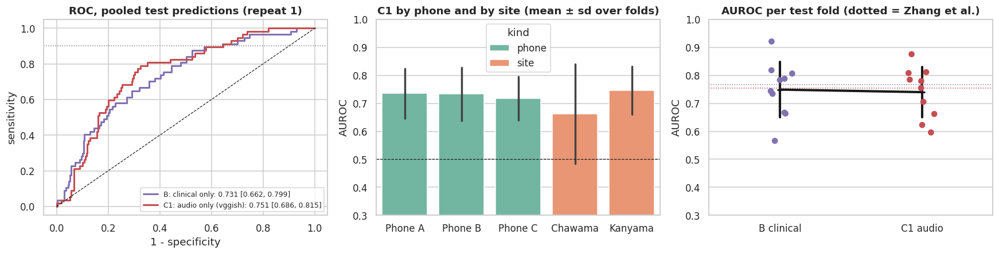

,model,participants,tb_pos,auroc_mean,auroc_sd,spec_at_90_sens
0,B clinical (cohort),325,57,0.749,0.094,0.358
1,C1 audio,325,57,0.740,0.086,0.354


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name, df, col in [("B: clinical only", clin_oof, "#8172B2"), (f"C1: audio only ({CFG['AUDIO_BACKEND']})", audio_subj, "#C44E52")]:
    g = df[df.repeat == 0]
    fpr, tpr, _ = roc_curve(g.label, g.score)
    lo, hi = boot_auc_ci(g.label, g.score)
    axes[0].plot(fpr, tpr, color=col, lw=2,
                 label=f"{name}: {roc_auc_score(g.label, g.score):.3f} [{lo:.3f}, {hi:.3f}]")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].axhline(0.9, color="grey", ls=":", lw=1)
axes[0].set(title="ROC, pooled test predictions (repeat 1)", xlabel="1 - specificity", ylabel="sensitivity")
axes[0].legend(fontsize=8, loc="lower right")

strat = []
for (r, k), g in audio_clips.groupby(["repeat", "fold"]):
    for dev in CFG["COHORT_DEVICES"]:
        s = subject_scores(g[g.device == dev])
        if s.label.nunique() == 2:
            strat.append(dict(group=dev, kind="phone", auroc=roc_auc_score(s.label, s.score)))
    s_all = subject_scores(g)
    for site in CFG["COHORT_SITES"]:
        s = s_all[s_all.subject_id.map(subj.site) == site]
        if s.label.nunique() == 2:
            strat.append(dict(group=site, kind="site", auroc=roc_auc_score(s.label, s.score)))
strat = pd.DataFrame(strat)
sns.barplot(data=strat, x="group", y="auroc", hue="kind", errorbar="sd", ax=axes[1], palette="Set2")
axes[1].axhline(0.5, color="k", lw=0.8, ls="--")
axes[1].set(title="C1 by phone and by site (mean ± sd over folds)", ylim=(0.3, 1), xlabel="", ylabel="AUROC")

both = pd.concat([b_folds.assign(model="B clinical"), c1_folds.assign(model="C1 audio")])
sns.stripplot(data=both, x="model", y="auroc", ax=axes[2], size=7, palette=["#8172B2", "#C44E52"])
sns.pointplot(data=both, x="model", y="auroc", ax=axes[2], color="k", errorbar="sd", markers="_")
axes[2].axhline(0.755, color="#C44E52", ls=":", lw=1); axes[2].axhline(0.767, color="#8172B2", ls=":", lw=1)
axes[2].set(title="AUROC per test fold (dotted = Zhang et al.)", xlabel="", ylabel="AUROC", ylim=(0.3, 1))
plt.tight_layout(); plt.show()

summary_rows = []
for name, df, ft in [("B clinical (cohort)", clin_oof, b_folds), ("C1 audio", audio_subj, c1_folds)]:
    g = df[df.repeat == 0]
    summary_rows.append(dict(model=name, participants=len(g), tb_pos=int(g.label.sum()),
                             auroc_mean=round(ft.auroc.mean(), 3), auroc_sd=round(ft.auroc.std(ddof=0), 3),
                             spec_at_90_sens=round(spec_at_sens(g.label, g.score), 3)))
results_table = pd.DataFrame(summary_rows)
display(results_table)

## Step 11. Audio alone versus clinical alone, on the same people

**What we do.** Compare C1 and B on exactly the participants both models scored, using DeLong's test for two AUROCs measured on the same people, and a bootstrap as a cross-check.

**Why.** Zhang et al. reported 0.755 for audio and 0.767 for clinical variables, but on different groups of people (about 650 versus 1,823), so those numbers cannot be compared directly. Here they can.

**How to read it.** Δ below zero means the questionnaire beat the cough model. The interval tells you how sure we can be: if it includes zero, the data cannot tell the two apart. This is **not** the project's main question (that is whether audio adds to clinical variables, Notebook 02), but it sets expectations.

In [33]:
def _midrank(x):
    order = np.argsort(x); z = x[order]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n); out[order] = t
    return out

def delong_paired(y, s1, s2):
    # Fast DeLong (Sun and Xu, 2014): difference of two correlated AUROCs, its 95% CI and p-value.
    y = np.asarray(y).astype(bool); m, n = y.sum(), (~y).sum()
    preds = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])
    tx = np.array([_midrank(p[y]) for p in preds]); ty = np.array([_midrank(p[~y]) for p in preds])
    tz = np.array([_midrank(np.concatenate([p[y], p[~y]])) for p in preds])
    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01, v10 = (tz[:, :m] - tx) / n, 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    diff = aucs[0] - aucs[1]
    se = np.sqrt(max(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1], 1e-12))
    return dict(auc_1=aucs[0], auc_2=aucs[1], delta=diff, ci_low=diff - 1.96 * se, ci_high=diff + 1.96 * se,
                p_value=2 * norm.sf(abs(diff / se)))

def boot_delta(y, s1, s2, n_boot=2000, seed=0):
    rng, y, s1, s2 = np.random.default_rng(seed), np.asarray(y), np.asarray(s1), np.asarray(s2)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    return np.percentile(d, [2.5, 97.5])

paired_rows = []
for r in range(CFG["N_REPEATS"]):
    m = audio_subj[audio_subj.repeat == r].merge(clin_oof[clin_oof.repeat == r][["subject_id", "score"]],
                                                 on="subject_id", suffixes=("_audio", "_clin"))
    dl = delong_paired(m.label, m.score_audio, m.score_clin)
    bl, bh = boot_delta(m.label, m.score_audio, m.score_clin, seed=r)
    paired_rows.append(dict(repeat=r + 1, participants=len(m), tb_pos=int(m.label.sum()),
                            auroc_audio=round(dl["auc_1"], 3), auroc_clinical=round(dl["auc_2"], 3),
                            delta_audio_minus_clinical=round(dl["delta"], 3),
                            delong_95ci=f"[{dl['ci_low']:.3f}, {dl['ci_high']:.3f}]",
                            bootstrap_95ci=f"[{bl:.3f}, {bh:.3f}]",
                            p_value=round(dl["p_value"], 3)))
paired_table = pd.DataFrame(paired_rows)
display(paired_table)

,repeat,participants,tb_pos,auroc_audio,auroc_clinical,delta_audio_minus_clinical,delong_95ci,bootstrap_95ci,p_value
0,1,325,57,0.751,0.731,0.020,"[-0.069, 0.109]","[-0.067, 0.112]",0.657
1,2,325,57,0.713,0.717,-0.004,"[-0.094, 0.086]","[-0.098, 0.087]",0.929


## Step 12. A first look: do the three phones agree?

**What we do.** For each test participant, compute a separate score from their Phone A clips, Phone B clips and Phone C clips, then plot the phones against each other.

**Why.** If the model listened only to the cough, the three scores would sit on the diagonal: same cough, same answer. Spread away from the diagonal is the device effect in action.

**Caution.** Here every model was trained on all three phones, so this *understates* the problem. Notebook 02 measures it properly, with the phone held out of training.

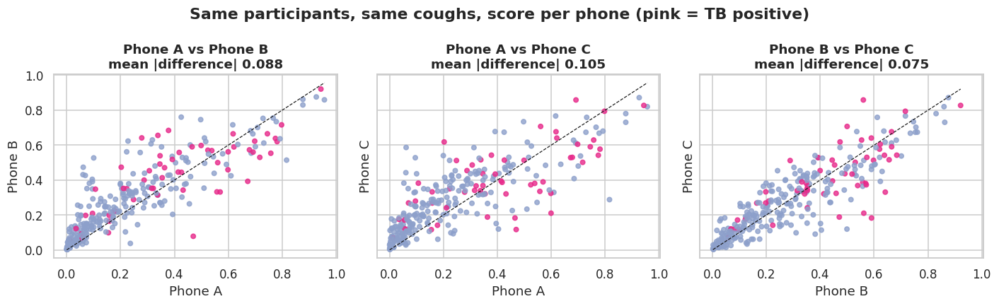

In [34]:
per_phone = subject_scores(audio_clips[audio_clips.repeat == 0], by=("subject_id", "device"))
wide = per_phone.pivot(index="subject_id", columns="device", values="score").dropna()
wide = wide.join(subj.label)
pairs = [("Phone A", "Phone B"), ("Phone A", "Phone C"), ("Phone B", "Phone C")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (a, b) in zip(axes, pairs):
    if a in wide and b in wide:
        ax.scatter(wide[a], wide[b], c=wide.label.map({0: "#8DA0CB", 1: "#E7298A"}), s=18, alpha=0.8)
        lim = (wide[[a, b]].min().min(), wide[[a, b]].max().max())
        ax.plot(lim, lim, "k--", lw=0.8)
        gap = (wide[a] - wide[b]).abs().mean()
        ax.set(title=f"{a} vs {b}\nmean |difference| {gap:.3f}", xlabel=a, ylabel=b)
fig.suptitle("Same participants, same coughs, score per phone (pink = TB positive)", fontweight="bold")
plt.tight_layout(); plt.show()

## Step 13. Save everything Notebook 02 needs

| File | Contents |
|---|---|
| `segmentation_manifest.csv`, `segmentation_qc.csv`, `segmented_coughs/` | Every cough clip and its quality information |
| `cohort_reproduction.csv`, `cohort_paired.csv` | Who is in each cohort |
| `folds.csv` | The shared test folds (reuse them, do not regenerate) |
| `clinical_oof.csv` | Baseline B score for each participant in each test fold |
| `audio_folds/<backend>/*.csv` | Baseline C1 score for every test clip from every inner model |
| `baseline_summary.json` | The headline numbers and the settings that produced them |

**Why out-of-fold scores matter for Notebook 02.** Late fusion feeds the audio score into a logistic regression next to the clinical variables. That audio score must come from a model that never saw the participant, otherwise it looks more reliable than it is and the fusion over-trusts it. These files are exactly such scores.

In [35]:
summary = dict(
    settings={k: CFG[k] for k in ("FAST_MODE", "N_REPEATS", "N_OUTER", "N_INNER", "EPOCHS",
                                  "COUGH_DETECTOR", "AUDIO_BACKEND", "COHORT_SITES", "COHORT_DEVICES")},
    cohort=dict(participants=int(len(subj)), tb_pos=int(subj.label.sum()), clips=int(len(coh)),
                paired_participants=len(paired_ids)),
    baseline_B=dict(auroc_mean=float(b_folds.auroc.mean()), auroc_sd=float(b_folds.auroc.std(ddof=0)),
                    full_metadata_auroc_mean=float(np.mean(full_auc)), full_metadata_auroc_sd=float(np.std(full_auc))),
    baseline_C1=dict(auroc_mean=float(c1_folds.auroc.mean()), auroc_sd=float(c1_folds.auroc.std(ddof=0))),
    paired_comparison=paired_table.to_dict(orient="records"),
    reference_zhang_et_al=dict(C1_within_zambia="0.755 ± 0.056", B_zambia="0.767 ± 0.025"),
)
(OUT / "baseline_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str)[:1500])
print("\nSaved to", OUT)

{
  "settings": {
    "FAST_MODE": false,
    "N_REPEATS": 2,
    "N_OUTER": 5,
    "N_INNER": 4,
    "EPOCHS": 40,
    "COUGH_DETECTOR": "clap",
    "AUDIO_BACKEND": "vggish",
    "COHORT_SITES": [
      "Chawama",
      "Kanyama"
    ],
    "COHORT_DEVICES": [
      "Phone A",
      "Phone B",
      "Phone C"
    ]
  },
  "cohort": {
    "participants": 325,
    "tb_pos": 57,
    "clips": 5287,
    "paired_participants": 299
  },
  "baseline_B": {
    "auroc_mean": 0.7490296042182836,
    "auroc_sd": 0.09386362385299142,
    "full_metadata_auroc_mean": 0.759270865670473,
    "full_metadata_auroc_sd": 0.02904330863005223
  },
  "baseline_C1": {
    "auroc_mean": 0.7399450479639158,
    "auroc_sd": 0.0858056299427573
  },
  "paired_comparison": [
    {
      "repeat": 1,
      "participants": 325,
      "tb_pos": 57,
      "auroc_audio": 0.751,
      "auroc_clinical": 0.731,
      "delta_audio_minus_clinical": 0.02,
      "delong_95ci": "[-0.069, 0.109]",
      "bootstrap_95ci": "[-0.0

## Step 14. Package everything for later

**What we do.** Save every table we built (several were only displayed on screen until now), then zip the results into the last bundle. All bundles live in `/kaggle/working/export/`:

| Bundle | Contents | Use it for |
|---|---|---|
| `zambia_segmented_coughs.zip` | every cough clip, the manifest, quality checks | skipping the ~1 h segmentation (`SEGMENTED_INPUT`); leave-one-phone-out training in Notebook 02 |
| `zambia_metadata_cohort.zip` | harmonised clinical variables, file inventory, relabel log applied, cohorts, **folds** | Notebook 02 must reuse these exact folds |
| `zambia_features_mel.zip` | mel spectrograms (clean and augmented), their indexes and settings | skipping feature extraction (`FEATURES_INPUT`) |
| `zambia_baseline_results.zip` | out-of-fold scores (clinical and audio), per-fold AUROCs, summary JSON, **all figures** | late fusion in Notebook 02, and the report |

Each zip contains a `README.txt`, and `export_manifest.json` records size, file count and a SHA-256 checksum per bundle, so you can confirm a download arrived intact.

**Moving the bundles to a new run.**
1. After this version finishes, open the notebook's **Output** tab and choose **New Dataset** (or download the zips and upload them as a dataset).
2. In the next notebook, **Add Data** → your dataset.
3. Point `SEGMENTED_INPUT` and/or `FEATURES_INPUT` at it, e.g. `"/kaggle/input/datasets/<you>/<name>"`. The notebook accepts either the zips or already-extracted folders, and extracts zips into `/kaggle/working/restored/` (the input folder is read-only).

In [36]:
if CFG["EXPORT"]:
    full_auc_df = pd.DataFrame({"fold": range(len(full_auc)), "auroc": full_auc})
    export_bundle("zambia_baseline_results", {
        "clinical_oof.csv": clin_oof,
        "clinical_fold_auroc.csv": b_folds,
        "clinical_full_metadata_fold_auroc.csv": full_auc_df,
        "audio_fold_auroc.csv": c1_folds,
        "audio_auroc_by_phone_and_site.csv": strat,
        "audio_subject_scores.csv": audio_subj,
        "audio_folds": OUT / "audio_folds",
        "phone_agreement_repeat1.csv": wide,
        "results_table.csv": results_table,
        "paired_comparison.csv": paired_table,
        "baseline_summary.json": OUT / "baseline_summary.json",
        "figures": FIG_DIR,
    }, "Baseline results: out-of-fold scores for clinical-only (B) and audio-only (C1) models on the "
       "shared folds, fold-level AUROCs, the paired comparison, the summary JSON and every figure.")

    m = json.loads((EXPORT_DIR / "export_manifest.json").read_text())
    listing = pd.DataFrame(m["bundles"]).T[["size_mb", "files", "sha256", "created"]]
    listing["sha256"] = listing.sha256.str[:16] + "..."
    display(listing)
    print(f"\nAll bundles are in {EXPORT_DIR}. Total: {listing.size_mb.astype(float).sum():.1f} MB")

Saved zambia_baseline_results.zip: 2.3 MB, 38 files, in 0 s


,size_mb,files,sha256,created
zambia_segmented_coughs,127.0,7318,872d8dd86eeaa107...,2026-10-12 21:24 UTC
zambia_metadata_cohort,0.1,13,ea84deb6a9fd90c8...,2026-10-12 21:24 UTC
zambia_features_mel,404.7,5,8eaaf35d5d8836ed...,2026-10-12 21:26 UTC
zambia_baseline_results,2.3,38,1846f25bc0743a03...,2026-10-12 22:31 UTC



All bundles are in /kaggle/working/export. Total: 534.1 MB


## What to take away, and what comes next

**Before trusting the numbers, check:**
1. Cohort counts in Step 7 are close to Zhang et al.'s table.
2. Few participants with zero clips, and the suspect-alignment list in Step 6c has been spot-checked by ear.
3. Baseline B on all participants lands near 0.767; if it does not, the clinical variables were mapped differently.
4. The run used `AUDIO_BACKEND = "vggish"`, `COUGH_DETECTOR = "clap"`, and ideally `FAST_MODE = False`.

**When reporting C1 against Zhang et al.,** state the two deviations: weights loaded by name, and a true best-epoch restore; and that test clips were not augmented.

**Notebook 02** reuses `folds.csv`, `clinical_oof.csv` and the audio fold files to build the late-fusion model (A1), introduces leave-one-phone-out training, and computes the two project metrics: the paired gain Δ = AUROC(fusion) − AUROC(clinical), and the device shift *D*.